# ERA5 t2m spatial gap filling: separate baseline experiments

**Research question:** Can training-learned spatial representations improve reconstruction of deliberately hidden daily temperature cells over harmonic interpolation?

Run the notebook from a **fresh kernel using Run All**. Set `DATA_DIR_OVERRIDE` in the configuration cell if automatic data discovery fails. Install missing packages in the active notebook kernel: numpy, pandas, xarray, netCDF4, scipy, scikit-learn, matplotlib, cartopy and a PyTorch build appropriate to your device. Cartopy may download Natural Earth features on first use.

This is a refactor of your supplied executed notebook. Data audit, eight-sample daily means, chronological split, training-only seasonal reference/scaling, identical masks, harmonic convergence checks, PCA/EOF visible-cell inference, ConvAE k sweep, spatial encoder-only Transformer, category analysis, checkpointing and geographic plots are retained.

**Presentation flow:** PCA/EOF versus interpolation; ConvAE versus interpolation; preserve the all-k learning curves and equal-k validation comparison; show the two best-k test comparisons side by side using identical axes; keep the Transformer as a separate model and the final four-method summary.

**New safeguards:** every training checkpoint must reproduce its best validation MSE when reloaded. The final single-map physical-unit validation path must also agree **before test scoring starts**. A mismatch stops execution and writes `validation_integrity.csv`; no disputed neural test ranking is silently accepted. A fresh output folder is created per run.

**Execution status:** outputs are intentionally cleared. This revision has not been trained or evaluated on your archive here. Do not interpret old conversation numbers as results of this revision.

**Windows saving update:** checkpoints use unique filenames and explicit binary streams. Code step 23 first checks a tiny save/load round trip. Error 1224 can indicate an open mapped file; the source process is not identified by this notebook. Start this revised version in a fresh kernel.

**CPU reference revision:** `DEVICE_OVERRIDE = "cpu"` is intentional. Start a fresh kernel and Run All so training, checkpoint selection, reloading and final evaluation all use CPU. Keep the same k candidates, masks, splits and training budgets. Earlier XPU metrics must not be combined with this new run. CPU training may be slower. Strict deterministic algorithms and validation-integrity checks remain enabled. This detects inconsistencies and does not guarantee that every future environment is reproducible.


**Code step 01**

## 1. Problem, motivation and reproducible protocol

**Purpose:** Fix the scientific question and configuration before evaluating models.

**Input:** NetCDF archive path and predeclared settings.

**Operation:** Set independent random seeds, output directory and experiment budgets.

**Output:** Protocol and reusable plotting helpers.

**Lecture connection:** Weather fields have D values but potentially smaller effective dimension.

**Expected shapes:** Fields [N,H,W]; network input [B,2,H,W]; output [B,1,H,W].

**Data leakage check:** No data-derived parameters are fitted here.

**Map styling:** Cartopy supplies the geographic projection, coastlines and borders; Matplotlib supplies the colormaps and scalar-field rendering. Temperature uses `RdYlBu_r`, anomalies use symmetric zero-centred `RdBu_r`, and absolute errors use `magma`. The selected colours resemble your teammate’s plots; their exact source library cannot be established from an image. Coastlines are a display layer; fields are not spatially regridded or smoothed.

In [102]:
# Code step 01
from pathlib import Path
import json, random, warnings, math, platform, hashlib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d
from sklearn.decomposition import PCA
from IPython.display import display, Markdown

DATA_DIR_OVERRIDE = None
DATA_CANDIDATES = [
    folder
    for base in (Path.cwd(), *Path.cwd().parents)
    for folder in (base / "homework3"/ "data", base / "homework3"/  "data"  )
]
DATA_DIR = (
    Path(DATA_DIR_OVERRIDE)
    if DATA_DIR_OVERRIDE
    else next(
        (
            folder
            for folder in DATA_CANDIDATES
            if folder.is_dir() and next(folder.rglob("*_instant.nc"), None)
        ),
        Path.cwd() / "data",
    )
)
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
OUTPUT_DIR = Path("model/t2m_gapfill_separate") / RUN_ID
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
VARIABLE_OVERRIDE = "t2m"
TRAIN_YEARS, VALIDATION_YEAR, TEST_YEAR = (set(range(2018, 2023)), 2023, 2024)
SEED, MASK_SEED, MASK_DRAWS = (42, 12000, 3)
BATCH_SIZE, MAX_EPOCHS, PATIENCE = (32, 40, 7)
INTERPOLATION_TOL, INTERPOLATION_MAX_ITER = (0.0001, 10000)
TEST_INDEX, DISPLAY_GAP, DISPLAY_DRAW = (0, "large", 0)
CLIMATOLOGY_WINDOW = 31
EXPECTED_HOURS = np.arange(0, 24, 3)
BOOTSTRAP_DRAWS = 1000
BOOTSTRAP_BLOCK_DAYS = 7
BOOTSTRAP_SEED = 45001
# Stop when reloaded weights do not reproduce the validation objective.
CHECKPOINT_RTOL, CHECKPOINT_ATOL = 1e-4, 1e-7
validation_integrity_rows = []
MIN_CATEGORY_DAYS = 20
np.random.seed(SEED)
random.seed(SEED)
try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
except ImportError as exc:
    raise ImportError(
        "Weather-map plotting requires cartopy. In this notebook kernel run: %pip install cartopy; then restart and Run All."
    ) from exc
from matplotlib.colors import TwoSlopeNorm

TEMPERATURE_CMAP = "RdYlBu_r"
ANOMALY_CMAP = "RdBu_r"
ERROR_CMAP = "magma"
MAP_CRS = ccrs.PlateCarree()


def map_subplots(*args, **kwargs):
    kwargs["subplot_kw"] = {"projection": MAP_CRS}
    return plt.subplots(*args, **kwargs)


def map_plot(ax, a, title, label, vmin=None, vmax=None, cmap=None):
    if not hasattr(ax, "coastlines"):
        raise TypeError("Use map_subplots to create geographic map axes")
    if cmap in {None, "coolwarm"}:
        cmap = TEMPERATURE_CMAP
    a = np.asarray(a)
    if a.shape != (len(latitude), len(longitude)):
        raise ValueError("Map shape must match latitude/longitude")
    if cmap == ANOMALY_CMAP:
        limit = max(
            abs(float(vmin)) if vmin is not None else 0.0,
            abs(float(vmax)) if vmax is not None else 0.0,
            float(np.nanmax(np.abs(a))) if vmin is None and vmax is None else 0.0,
            1e-06,
        )
        norm = TwoSlopeNorm(vmin=-limit, vcenter=0.0, vmax=limit)
        im = ax.pcolormesh(
            longitude,
            latitude,
            np.ma.masked_invalid(a),
            shading="auto",
            cmap=cmap,
            norm=norm,
            transform=MAP_CRS,
        )
    else:
        im = ax.pcolormesh(
            longitude,
            latitude,
            np.ma.masked_invalid(a),
            shading="auto",
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            transform=MAP_CRS,
        )
    ax.set_extent(
        [
            float(np.min(longitude)),
            float(np.max(longitude)),
            float(np.min(latitude)),
            float(np.max(latitude)),
        ],
        crs=MAP_CRS,
    )
    ax.coastlines(resolution="50m", linewidth=0.65, color="black")
    ax.add_feature(cfeature.BORDERS.with_scale("50m"), linewidth=0.35, linestyle=":")
    grid = ax.gridlines(
        crs=MAP_CRS,
        draw_labels=True,
        linewidth=0.35,
        color="gray",
        alpha=0.45,
        linestyle="--",
        x_inline=False,
        y_inline=False,
    )
    grid.top_labels = False
    grid.right_labels = False
    grid.xformatter = LongitudeFormatter()
    grid.yformatter = LatitudeFormatter()
    grid.xlabel_style = {"size": 8}
    grid.ylabel_style = {"size": 8}
    ax.set_title(title, fontsize=10)
    cax = ax.inset_axes([1.035, 0.0, 0.035, 1.0])
    bar = plt.colorbar(im, cax=cax)
    bar.set_label(label, fontsize=9)
    bar.ax.tick_params(labelsize=8)
    return im


print(
    "Weather-map styling: Cartopy PlateCarree/50m coastlines; t2m RdYlBu_r; anomalies RdBu_r centered on zero; errors magma."
)
print(
    "Cartopy downloads Natural Earth coastlines/borders on first use; an internet connection or a populated Cartopy data cache is needed."
)
print("Task: same-day t2m gap filling, not forecasting.")
print("Data directory:", DATA_DIR.resolve())
print("Train/validation/test:", sorted(TRAIN_YEARS), VALIDATION_YEAR, TEST_YEAR)
CONV_LATENT_DIMS = [8, 16, 32, 64, 128]
TRANSFORMER_CONFIG = dict(patch_size=4, d=64, nhead=4, nlayers=2, d_ff=128)
LEARNING_RATES = {"ConvAE": 0.001, "Spatial Transformer": 0.0003}
METHODS = ["Interpolation", "PCA/EOF", "ConvAE", "Spatial Transformer"]
print(
    "Compared methods:",
    METHODS,
    "; fixed architecture settings:",
    CONV_LATENT_DIMS,
    TRANSFORMER_CONFIG,
)

EOF_RIDGE = (
    1e-6  # Fixed ridge stabilizes visible-cell coefficient estimation; not tuned on test.
)

print("Outputs and fresh checkpoints:", OUTPUT_DIR.resolve())


Weather-map styling: Cartopy PlateCarree/50m coastlines; t2m RdYlBu_r; anomalies RdBu_r centered on zero; errors magma.
Cartopy downloads Natural Earth coastlines/borders on first use; an internet connection or a populated Cartopy data cache is needed.
Task: same-day t2m gap filling, not forecasting.
Data directory: S:\git-repo\pgr\py-torch\courses\STAT41140-AI for Weather and Climate\homework3\data
Train/validation/test: [2018, 2019, 2020, 2021, 2022] 2023 2024
Compared methods: ['Interpolation', 'PCA/EOF', 'ConvAE', 'Spatial Transformer'] ; fixed architecture settings: [8, 16, 32, 64, 128] {'patch_size': 4, 'd': 64, 'nhead': 4, 'nlayers': 2, 'd_ff': 128}
Outputs and fresh checkpoints: S:\git-repo\pgr\py-torch\courses\STAT41140-AI for Weather and Climate\homework3\model\t2m_gapfill_separate\20261020T085548_522148Z


# Step 2 

**Code step 02**

## 2a. Inspect every NetCDF before modeling

**Purpose:** What variables, coordinates, units and timestamps actually exist?

**Input:** Every NetCDF under DATA_DIR.

**Operation:** Decode CF fill/scale/time metadata; inspect every variable; calculate exact finite-value statistics and interval counts.

**Output:** file_audit.csv plus detailed metadata JSON and candidate records.

**Lecture connection:** Define the observed weather field x before choosing its representation.

**Expected shapes:** Reported separately per variable; unsupported extra dimensions are not squeezed silently.

**Data leakage check:** Audit only; no preprocessing fit.

In [103]:
# Code step 02
def coordinate_name(ds, standard, aliases):
    names = [c for c in ds.coords if ds[c].attrs.get("standard_name") == standard]
    names += [c for c in aliases if c in ds.coords and c not in names]
    if not names:
        raise ValueError(f"Missing coordinate {standard}")
    return names[0]


def is_temperature(a):
    return a.name == "t2m" or (
        a.attrs.get("standard_name") == "air_temperature"
        and "2 metre" in str(a.attrs.get("long_name", "")).lower()
    )


def audit_files(root):
    paths = sorted(
        (p for p in root.rglob("*") if p.suffix.lower() in {".nc", ".nc4", ".netcdf"})
    )
    if not paths:
        raise FileNotFoundError(f"No NetCDF files under {root.resolve()}")
    rows, records, metadata = ([], [], [])
    for p in paths:
        with xr.open_dataset(p, decode_cf=True, mask_and_scale=True) as ds:
            print("\nFILE:", p, "variables:", list(ds.data_vars), "dimensions:", dict(ds.sizes))
            meta = {
                "file": str(p),
                "global": dict(ds.attrs),
                "coordinates": {},
                "variables": {},
            }
            for c in ds.coords:
                meta["coordinates"][c] = {"dims": list(ds[c].dims), "attrs": dict(ds[c].attrs)}
            for v, a in ds.data_vars.items():
                print(v, dict(a.attrs), "dims", a.dims)
                meta["variables"][v] = {
                    "attrs": dict(a.attrs),
                    "encoding": {
                        k: a.encoding[k]
                        for k in ["_FillValue", "missing_value", "scale_factor", "add_offset"]
                        if k in a.encoding
                    },
                    "dims": list(a.dims),
                }
                if not np.issubdtype(a.dtype, np.number):
                    continue
                x = np.asarray(a.values)
                finite = x[np.isfinite(x)]
                row = {
                    "file": p.name,
                    "variable": v,
                    "long_name": a.attrs.get("long_name"),
                    "standard_name": a.attrs.get("standard_name"),
                    "units": a.attrs.get("units"),
                    "dimensions": str(dict(a.sizes)),
                    "missing": int((~np.isfinite(x)).sum()),
                }
                if finite.size:
                    row.update(
                        zip(
                            ["min", "median", "p95", "p99", "max"],
                            np.percentile(finite, [0, 50, 95, 99, 100]),
                        )
                    )
                    row["zero_percent"] = 100 * float(np.mean(finite == 0))
                try:
                    tn = coordinate_name(ds, "time", ["valid_time", "time"])
                    yn = coordinate_name(ds, "latitude", ["latitude", "lat"])
                    xn = coordinate_name(ds, "longitude", ["longitude", "lon"])
                    times = pd.DatetimeIndex(ds[tn].values)
                    if times.hasnans:
                        raise ValueError("NaT timestamp")
                    delta = (
                        pd.Series((times[1:] - times[:-1]).total_seconds() / 3600.0)
                        .value_counts()
                        .sort_index()
                        .to_dict()
                    )
                    row.update(
                        time_start=str(times.min()),
                        time_end=str(times.max()),
                        frames=len(times),
                        duplicate_times=int(times.duplicated().sum()),
                        sampling_hours=str(delta),
                        latitude_range=str([float(ds[yn].min()), float(ds[yn].max())]),
                        longitude_range=str([float(ds[xn].min()), float(ds[xn].max())]),
                        grid_shape=str((ds.sizes[yn], ds.sizes[xn])),
                    )
                    print(
                        "Time range / spacing / grid:",
                        row["time_start"],
                        row["time_end"],
                        delta,
                        row["grid_shape"],
                    )
                    if is_temperature(a) or v == VARIABLE_OVERRIDE:
                        records.append(
                            {"path": p, "variable": v, "time": tn, "lat": yn, "lon": xn}
                        )
                except (ValueError, TypeError, KeyError) as e:
                    row["coordinate_issue"] = str(e)
                rows.append(row)
            metadata.append(meta)
    table = pd.DataFrame(rows)
    display(table)
    table.to_csv(OUTPUT_DIR / "file_audit.csv", index=False)
    (OUTPUT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2, default=str), encoding="utf-8")
    return (table, records, metadata)


file_audit, candidates, metadata = audit_files(DATA_DIR)



FILE: s:\git-repo\pgr\py-torch\courses\STAT41140-AI for Weather and Climate\homework3\data\2018_accum.nc variables: ['tp'] dimensions: {'valid_time': 3285, 'latitude': 41, 'longitude': 89}
tp {'GRIB_paramId': np.int64(228), 'GRIB_dataType': 'fc', 'GRIB_numberOfPoints': np.int64(3649), 'GRIB_typeOfLevel': 'surface', 'GRIB_stepUnits': np.int64(1), 'GRIB_stepType': 'accum', 'GRIB_gridType': 'regular_ll', 'GRIB_uvRelativeToGrid': np.int64(0), 'GRIB_NV': np.int64(0), 'GRIB_Nx': np.int64(89), 'GRIB_Ny': np.int64(41), 'GRIB_cfName': 'unknown', 'GRIB_cfVarName': 'tp', 'GRIB_gridDefinitionDescription': 'Latitude/Longitude Grid', 'GRIB_iDirectionIncrementInDegrees': np.float64(0.25), 'GRIB_iScansNegatively': np.int64(0), 'GRIB_jDirectionIncrementInDegrees': np.float64(0.25), 'GRIB_jPointsAreConsecutive': np.int64(0), 'GRIB_jScansPositively': np.int64(0), 'GRIB_latitudeOfFirstGridPointInDegrees': np.float64(58.0), 'GRIB_latitudeOfLastGridPointInDegrees': np.float64(48.0), 'GRIB_longitudeOfFirstG

,file,variable,long_name,standard_name,units,dimensions,missing,min,median,p95,...,max,zero_percent,time_start,time_end,frames,duplicate_times,sampling_hours,latitude_range,longitude_range,grid_shape
0,2018_accum.nc,tp,Total precipitation,unknown,m,"{'valid_time': 3285, 'latitude': 41, 'longitud...",0,0.000000,0.000022,0.000838,...,0.019503,20.618881,2018-01-01 00:00:00,2018-12-31 21:00:00,3285,0,"{1.0: 365, 2.0: 365, 3.0: 2554}","[48.0, 58.0]","[-25.0, -3.0]","(41, 89)"
1,2018_instant.nc,u10,10 metre U wind component,unknown,m s**-1,"{'valid_time': 3285, 'latitude': 41, 'longitud...",0,-29.424438,3.103119,13.499100,...,28.822937,0.000050,2018-01-01 00:00:00,2018-12-31 21:00:00,3285,0,"{1.0: 365, 2.0: 365, 3.0: 2554}","[48.0, 58.0]","[-25.0, -3.0]","(41, 89)"
2,2018_instant.nc,v10,10 metre V wind component,unknown,m s**-1,"{'valid_time': 3285, 'latitude': 41, 'longitud...",0,-25.335373,1.256317,12.114713,...,27.881927,0.000083,2018-01-01 00:00:00,2018-12-31 21:00:00,3285,0,"{1.0: 365, 2.0: 365, 3.0: 2554}","[48.0, 58.0]","[-25.0, -3.0]","(41, 89)"
3,2018_instant.nc,d2m,2 metre dewpoint temperature,unknown,K,"{'valid_time': 3285, 'latitude': 41, 'longitud...",0,257.892334,280.511963,287.484863,...,292.902344,0.000000,2018-01-01 00:00:00,2018-12-31 21:00:00,3285,0,"{1.0: 365, 2.0: 365, 3.0: 2554}","[48.0, 58.0]","[-25.0, -3.0]","(41, 89)"
4,2018_instant.nc,t2m,2 metre temperature,unknown,K,"{'valid_time': 3285, 'latitude': 41, 'longitud...",0,259.637451,283.934570,289.655273,...,304.362305,0.000000,2018-01-01 00:00:00,2018-12-31 21:00:00,3285,0,"{1.0: 365, 2.0: 365, 3.0: 2554}","[48.0, 58.0]","[-25.0, -3.0]","(41, 89)"
5,2018_instant.nc,msl,Mean sea level pressure,air_pressure_at_mean_sea_level,Pa,"{'valid_time': 3285, 'latitude': 41, 'longitud...",0,94048.062500,101351.000000,103028.862500,...,104657.750000,0.000000,2018-01-01 00:00:00,2018-12-31 21:00:00,3285,0,"{1.0: 365, 2.0: 365, 3.0: 2554}","[48.0, 58.0]","[-25.0, -3.0]","(41, 89)"
6,2019_accum.nc,tp,Total precipitation,unknown,m,"{'valid_time': 3285, 'latitude': 41, 'longitud...",0,0.000000,0.000022,0.000833,...,0.016609,20.675534,2019-01-01 00:00:00,2019-12-31 21:00:00,3285,0,"{1.0: 365, 2.0: 365, 3.0: 2554}","[48.0, 58.0]","[-25.0, -3.0]","(41, 89)"
7,2019_instant.nc,u10,10 metre U wind component,unknown,m s**-1,"{'valid_time': 3285, 'latitude': 41, 'longitud...",0,-24.111313,2.854309,13.559903,...,27.117905,0.000075,2019-01-01 00:00:00,2019-12-31 21:00:00,3285,0,"{1.0: 365, 2.0: 365, 3.0: 2554}","[48.0, 58.0]","[-25.0, -3.0]","(41, 89)"
8,2019_instant.nc,v10,10 metre V wind component,unknown,m s**-1,"{'valid_time': 3285, 'latitude': 41, 'longitud...",0,-24.066193,0.917587,11.748834,...,24.712250,0.000108,2019-01-01 00:00:00,2019-12-31 21:00:00,3285,0,"{1.0: 365, 2.0: 365, 3.0: 2554}","[48.0, 58.0]","[-25.0, -3.0]","(41, 89)"
9,2019_instant.nc,d2m,2 metre dewpoint temperature,unknown,K,"{'valid_time': 3285, 'latitude': 41, 'longitud...",0,259.942383,281.240479,287.530518,...,296.801270,0.000000,2019-01-01 00:00:00,2019-12-31 21:00:00,3285,0,"{1.0: 365, 2.0: 365, 3.0: 2554}","[48.0, 58.0]","[-25.0, -3.0]","(41, 89)"


**Code step 03**

## 2b. Resolve t2m units and temporal definition

**Purpose:** Which audited field is temperature, and how is it converted?

**Input:** Metadata candidates from all files.

**Operation:** Select t2m, validate units/instantaneous semantics and declare eight-sample daily means.

**Output:** Temperature-file records and explicit unit report.

**Lecture connection:** Define the physical field x before representation learning.

**Expected shapes:** Source [T,H,W]; no accumulated-precipitation intervals.

**Data leakage check:** Metadata only; no fitted statistics.



In [104]:
# Code step 03
variables = sorted({r["variable"] for r in candidates})
VARIABLE = VARIABLE_OVERRIDE or (variables[0] if len(variables) == 1 else None)
if VARIABLE is None or VARIABLE not in variables:
    raise ValueError(f"No uniquely selected t2m field. Audited candidates: {variables}")
temperature_records = [r for r in candidates if r["variable"] == VARIABLE]
for r in temperature_records:
    with xr.open_dataset(r["path"]) as ds:
        units = str(ds[VARIABLE].attrs.get("units", "")).strip().lower()
        if units not in {"k", "kelvin", "degc", "degree_celsius", "degrees_celsius", "°c"}:
            raise ValueError(f"Unsupported temperature units {units!r}; inspect metadata")
        if ds[VARIABLE].attrs.get("GRIB_stepType", "instant") != "instant":
            raise ValueError("Expected instantaneous t2m; inspect temporal semantics")
        print(
            r["path"].name,
            "variable:",
            VARIABLE,
            "units:",
            units,
            "→ °C; instantaneous samples",
        )
print(
    "Retained temperature files:",
    len(temperature_records),
    "(other audited variables are not modeled)",
)


2018_instant.nc variable: t2m units: k → °C; instantaneous samples
2019_instant.nc variable: t2m units: k → °C; instantaneous samples
2020_instant.nc variable: t2m units: k → °C; instantaneous samples
2021_instant.nc variable: t2m units: k → °C; instantaneous samples
2022_instant.nc variable: t2m units: k → °C; instantaneous samples
2023_instant.nc variable: t2m units: k → °C; instantaneous samples
2024_instant.nc variable: t2m units: k → °C; instantaneous samples
Retained temperature files: 7 (other audited variables are not modeled)


**Code step 04**

## 3. Construct daily sampled-mean t2m

**Purpose:** Which days have all eight required samples?

**Input:** Audited instantaneous t2m files and decoded timestamps.

**Operation:** Convert Kelvin to Celsius; reject duplicates, mismatched grids and incomplete/non-finite days. Remove off-protocol timestamps explicitly.

**Output:** Daily fields X, dates, daily audit and example maps.

**Lecture connection:** Physical definition of the map x.

**Expected shapes:** X [N,H,W]; dates [N]; grid [H] and [W].

**Data leakage check:** Fixed data-quality protocol; no preprocessing fit.



Off-protocol samples removed: 2557 ; expected hours: [0, 3, 6, 9, 12, 15, 18, 21]


,calendar_days,retained_days
date,,
2018,365,365
2019,365,365
2020,366,366
2021,365,365
2022,365,365
2023,365,365
2024,366,366


Daily shape: (2557, 41, 89) units: °C; mean of eight 3-hourly samples


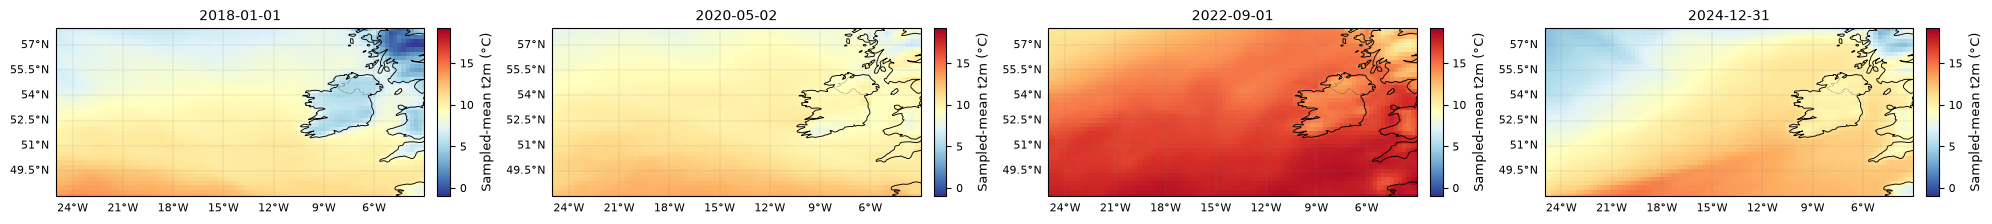

In [105]:
# Code step 04
def make_temperature_daily(records):
    maps = []
    times = []
    latitude = longitude = None
    for r in records:
        with xr.open_dataset(r["path"]) as ds:
            a = ds[r["variable"]]
            if set(a.dims) != {r["time"], r["lat"], r["lon"]}:
                raise ValueError(
                    f"Unexpected dimensions {a.dims}; explicitly select member/level"
                )
            lat, lon = (ds[r["lat"]].values, ds[r["lon"]].values)
            if lat.ndim != 1 or lon.ndim != 1:
                raise ValueError("Expected rectilinear grid")
            if latitude is None:
                latitude, longitude = (lat.copy(), lon.copy())
            elif not (np.array_equal(latitude, lat) and np.array_equal(longitude, lon)):
                raise ValueError("Inconsistent grids")
            for coord in [lat, lon]:
                if not np.isfinite(coord).all() or not (
                    np.all(np.diff(coord) > 0) or np.all(np.diff(coord) < 0)
                ):
                    raise ValueError("Invalid coordinate ordering")
            x = a.transpose(r["time"], r["lat"], r["lon"]).values.astype("float64")
            units = str(a.attrs["units"]).lower()
            if units in {"k", "kelvin"}:
                x = x - 273.15
            if np.any(np.isfinite(x) & ((x < -100) | (x > 70))):
                raise ValueError("Implausible 2-metre temperatures; inspect units/data")
            maps.append(x)
            times.extend(ds[r["time"]].values)
    x = np.concatenate(maps)
    t = pd.DatetimeIndex(times)
    # Reject duplicate dates rather than averaging overlapping files.
    if t.hasnans or t.duplicated().any():
        raise ValueError(
            "Invalid/duplicate timestamps; resolve overlapping files rather than averaging duplicates"
        )
    order = np.argsort(t.asi8)
    x, t = (x[order], t[order])
    # Keep the same eight three-hourly samples on every retained day.
    on_grid = (
        np.isin(t.hour, EXPECTED_HOURS)
        & (t.minute == 0)
        & (t.second == 0)
        & (t.microsecond == 0)
        & (t.nanosecond == 0)
    )
    print(
        "Off-protocol samples removed:",
        int((~on_grid).sum()),
        "; expected hours:",
        EXPECTED_HOURS.tolist(),
    )
    x, t = (x[on_grid], t[on_grid])
    if not len(t):
        raise ValueError("No expected samples")
    rows = []
    daily = []
    split_dates = []
    for day in pd.date_range(t.min().normalize(), t.max().normalize()):
        ix = np.flatnonzero(t.normalize() == day)
        complete = len(ix) == 8 and np.array_equal(t[ix].hour, EXPECTED_HOURS)
        finite = bool(len(ix) and np.isfinite(x[ix]).all())
        keep = complete and finite
        rows.append(
            dict(date=day, samples=len(ix), complete=complete, finite=finite, retained=keep)
        )
        if keep:
            daily.append(x[ix].mean(axis=0))
            split_dates.append(day)
    audit = pd.DataFrame(rows)
    audit.to_csv(OUTPUT_DIR / "daily_audit.csv", index=False)
    display(
        audit.groupby(audit.date.dt.year).agg(
            calendar_days=("date", "size"), retained_days=("retained", "sum")
        )
    )
    if not daily:
        raise ValueError("No complete daily sampled means")
    return (
        np.stack(daily).astype("float32"),
        pd.DatetimeIndex(split_dates),
        latitude,
        longitude,
        audit,
    )


daily_temperature_maps, daily_dates, latitude, longitude, daily_audit = make_temperature_daily(
    temperature_records
)
map_height, map_width = daily_temperature_maps.shape[1:]
grid_cell_count = map_height * map_width
print("Daily shape:", daily_temperature_maps.shape, "units: °C; mean of eight 3-hourly samples")
indices = np.linspace(
    0, len(daily_temperature_maps) - 1, min(4, len(daily_temperature_maps)), dtype=int
)
fig, axes = map_subplots(1, len(indices), figsize=(5 * len(indices), 4), squeeze=False)
vmin, vmax = (
    float(daily_temperature_maps[indices].min()),
    float(daily_temperature_maps[indices].max()),
)
for ax, i in zip(axes.flat, indices):
    map_plot(
        ax,
        daily_temperature_maps[i],
        str(daily_dates[i].date()),
        "Sampled-mean t2m (°C)",
        vmin,
        vmax,
        TEMPERATURE_CMAP,
    )
plt.tight_layout()
plt.show()


**Figure interpretation:** Preselected days share a Celsius colour scale. These are means of eight three-hourly samples, not full-hourly daily means, daily extremes or forecasts.

**Code step 05**

## 4. Chronological split

**Purpose:** Are all required years actually available?

**Input:** Daily maps and decoded dates.

**Operation:** Retain 2018–2022 training, 2023 validation, 2024 test; fail if any required year is absent.

**Output:** Physical fields and dates by split.

**Lecture connection:** Held-out reconstruction and honest model selection.

**Expected shapes:** Each split [N_split,H,W].

**Data leakage check:** Splits precede all climatology and scaling fits.

In [106]:
# Code step 05
missing = sorted((TRAIN_YEARS | {VALIDATION_YEAR, TEST_YEAR}) - set(daily_dates.year))
if missing:
    raise ValueError(
        f"Missing temperature years {missing}; obtain the complete archive. No fallback split is invented."
    )
# Assign split membership from decoded years, never filenames.
selectors = {
    "train": np.isin(daily_dates.year, list(TRAIN_YEARS)),
    "validation": daily_dates.year == VALIDATION_YEAR,
    "test": daily_dates.year == TEST_YEAR,
}
temperature_maps = {s: daily_temperature_maps[ix] for s, ix in selectors.items()}
split_dates = {s: daily_dates[ix] for s, ix in selectors.items()}
for s in temperature_maps:
    if not len(temperature_maps[s]):
        raise ValueError(f"Empty {s}")
    print(s, len(temperature_maps[s]), split_dates[s].min(), split_dates[s].max())
assert split_dates["train"].max() < split_dates["validation"].min() < split_dates["test"].min()


train 1826 2018-01-01 00:00:00 2022-12-31 00:00:00
validation 365 2023-01-01 00:00:00 2023-12-31 00:00:00
test 366 2024-01-01 00:00:00 2024-12-31 00:00:00


**Code step 06**

## 5. Training-only 365-day temperature climatology

**Purpose:** What is the expected seasonal temperature map?

**Input:** Training fields and dates only.

**Operation:** Map Feb 29 to Feb 28; map later leap dates to a 365-day calendar. Compute mean per slot and circular 31-day smoothing. Report median sensitivity.

**Output:** climatology [365,H,W] and per-slot sample counts.

**Lecture connection:** Seasonal background removal before representation learning.

**Expected shapes:** Climatology [365,H,W], slot index [N].

**Data leakage check:** Fit only 2018–2022; freeze for validation/test.

In [107]:
# Code step 06
def slots365(index):
    index = pd.DatetimeIndex(index)
    slots = index.dayofyear.to_numpy() - 1
    slots = slots - (index.is_leap_year & (index.month > 2)).astype(int)
    slots[(index.month == 2) & (index.day == 29)] = 58
    return slots


# Only training days contribute to the seasonal reference.
train_slots = slots365(split_dates["train"])
raw_clim = []
med_clim = []
counts = []
for day in range(365):
    a = temperature_maps["train"][train_slots == day]
    counts.append(len(a))
    raw_clim.append(a.mean(axis=0) if len(a) else np.full((map_height, map_width), np.nan))
    med_clim.append(
        np.median(a, axis=0) if len(a) else np.full((map_height, map_width), np.nan)
    )
raw_clim = np.stack(raw_clim)
med_clim = np.stack(med_clim)
w = np.asarray(counts, dtype=float)[:, None, None]
# Wrap the seasonal window across 31 December / 1 January.
num = uniform_filter1d(np.nan_to_num(raw_clim) * w, CLIMATOLOGY_WINDOW, axis=0, mode="wrap")
den = uniform_filter1d(w, CLIMATOLOGY_WINDOW, axis=0, mode="wrap")
if np.any(den == 0):
    raise ValueError("No training samples in a climatological window")
climatology = (num / den).astype("float32")
print(
    "Samples per slot:",
    min(counts),
    max(counts),
    "mean absolute mean–median difference (°C):",
    float(np.nanmean(np.abs(raw_clim - med_clim))),
)
print(
    "Climatology shape:",
    climatology.shape,
    "; 31-day circular mean; median difference is a sensitivity diagnostic, not a replacement.",
)
np.savez_compressed(
    OUTPUT_DIR / "preprocessing_climatology.npz",
    climatology=climatology,
    counts=counts,
    latitude=latitude,
    longitude=longitude,
)


Samples per slot: 5 6 mean absolute mean–median difference (°C): 0.3671238422393799
Climatology shape: (365, 41, 89) ; 31-day circular mean; median difference is a sensitivity diagnostic, not a replacement.


**Code step 07**

## 6. Climatological anomalies

**Purpose:** Where is a day warmer/colder than its seasonal expectation?

**Input:** Physical fields and frozen training climatology.

**Operation:** A(t)=X(t)−climatology[day slot]. Plot training anomaly distribution.

**Output:** Anomalies and day-specific backgrounds for every split.

**Lecture connection:** Separate seasonality from the representation to learn.

**Expected shapes:** A and background [N_split,H,W].

**Data leakage check:** All backgrounds come from training only; distribution here uses training.

Anomaly mean / SD / percentiles (°C): -4.9057685e-06 1.5509855 [-16.24738312  -4.05462782  -2.60539968   0.06149483   2.35762851
   3.5772879   12.94004631]


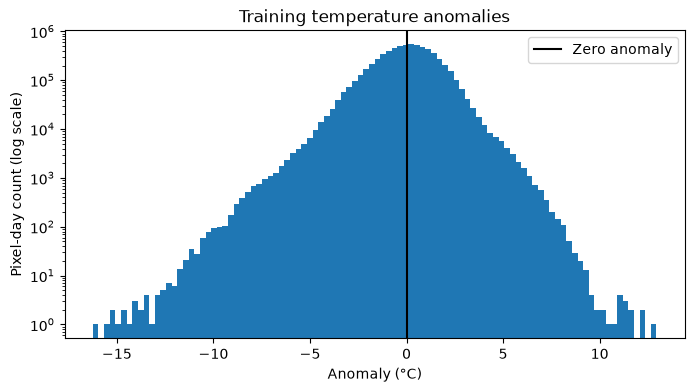

In [108]:
# Code step 07
seasonal_reference = {s: climatology[slots365(split_dates[s])] for s in temperature_maps}
temperature_anomalies = {
    s: temperature_maps[s] - seasonal_reference[s] for s in temperature_maps
}
a = temperature_anomalies["train"].ravel()
print(
    "Anomaly mean / SD / percentiles (°C):",
    a.mean(),
    a.std(),
    np.percentile(a, [0, 1, 5, 50, 95, 99, 100]),
)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(a, bins=100, log=True)
ax.axvline(0, color="black", label="Zero anomaly")
ax.set(
    title="Training temperature anomalies",
    xlabel="Anomaly (°C)",
    ylabel="Pixel-day count (log scale)",
)
ax.legend()
plt.show()


**Figure interpretation:** Positive anomalies are warmer than seasonal expectation; negative anomalies are colder. Zero anomaly does not mean 0 °C. The full training histogram describes the residual distribution.

**Code step 08**

## 7. Standardize anomalies using training data

**Purpose:** Is lecture-aligned SD scaling numerically sensible?

**Input:** Training anomalies.

**Operation:** Estimate one global training anomaly SD; divide anomalies without ordinary global centring. Report skew/tail diagnostics.

**Output:** Z=A/SD_train; exact reversible scale.

**Lecture connection:** Standardization follows climatology removal rather than replacing it.

**Expected shapes:** Z [N_split,H,W]; SD_train scalar in °C.

**Data leakage check:** SD and diagnostics use training only.

In [109]:
# Code step 08
# Fit this scale on training anomalies only.
training_anomaly_std = float(np.std(temperature_anomalies["train"], dtype=np.float64))
if not np.isfinite(training_anomaly_std) or training_anomaly_std <= 1e-12:
    raise ValueError("Degenerate anomaly SD")
standardized_anomalies = {
    s: (temperature_anomalies[s] / training_anomaly_std).astype("float32")
    for s in temperature_maps
}
if not all((np.isfinite(z).all() for z in standardized_anomalies.values())):
    raise ValueError("Non-finite standardized anomaly")
z = standardized_anomalies["train"].ravel().astype("float64")
print(
    "SD_train (°C):",
    training_anomaly_std,
    "Z mean/SD:",
    z.mean(),
    z.std(),
    "max |Z|:",
    np.abs(z).max(),
    "fraction |Z|>10:",
    np.mean(np.abs(z) > 10),
    "third central moment (dimensionless):",
    np.mean((z - z.mean()) ** 3),
)
print(
    "Training anomaly mean/SD and tails are diagnostics only. Scaling does not establish linearity or normality; no log transform is used."
)
np.save(OUTPUT_DIR / "SD_train.npy", np.array(training_anomaly_std))


SD_train (°C): 1.550985477373739 Z mean/SD: -3.1649586378694297e-06 1.0000000141022147 max |Z|: 10.475522994995117 fraction |Z|>10: 1.5008087858546972e-07 third central moment (dimensionless): -0.28147859424710847
Training anomaly mean/SD and tails are diagnostics only. Scaling does not establish linearity or normality; no log transform is used.


**Code step 09**

## 8. Visualize raw fields, climatology, anomalies and standardized anomalies

**Purpose:** What does each preprocessing stage mean?

**Input:** First training day and training-only distributions.

**Operation:** Plot four aligned maps and raw/anomaly/Z histograms.

**Output:** Preprocessing figures in physical and dimensionless units.

**Lecture connection:** Input representation and interpretation of standardized x.

**Expected shapes:** Four [H,W] maps; distributions over training pixel-days.

**Data leakage check:** Training examples only.

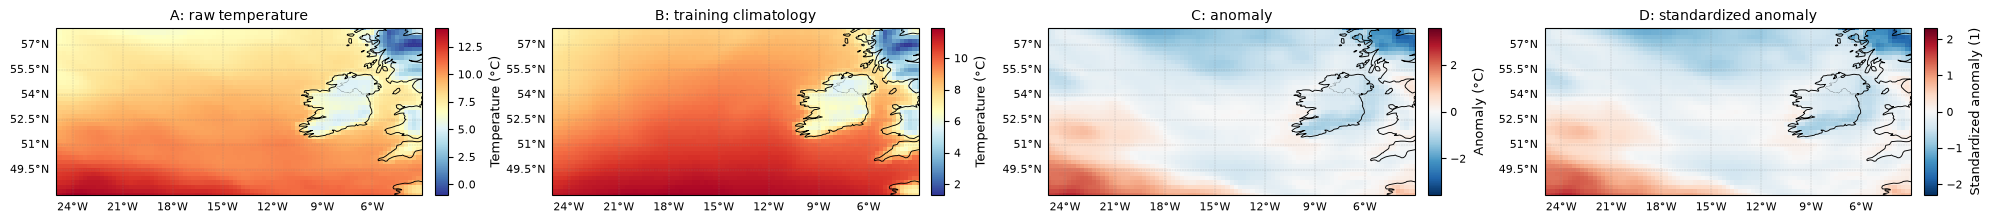

In [110]:
# Code step 09
i = 0
fig, axes = map_subplots(1, 4, figsize=(20, 4))
map_plot(
    axes[0],
    temperature_maps["train"][i],
    "A: raw temperature",
    "Temperature (°C)",
    cmap=TEMPERATURE_CMAP,
)
map_plot(
    axes[1],
    seasonal_reference["train"][i],
    "B: training climatology",
    "Temperature (°C)",
    cmap=TEMPERATURE_CMAP,
)
a = temperature_anomalies["train"][i]
lim = float(np.abs(a).max()) or 1.0
map_plot(axes[2], a, "C: anomaly", "Anomaly (°C)", -lim, lim, "RdBu_r")
map_plot(
    axes[3],
    standardized_anomalies["train"][i],
    "D: standardized anomaly",
    "Standardized anomaly (1)",
    -lim / training_anomaly_std,
    lim / training_anomaly_std,
    "RdBu_r",
)
plt.tight_layout()
plt.show()


**Figure interpretation:** The four maps distinguish physical temperature, seasonal expectation, anomaly and dimensionless anomaly. Signed anomaly scales are centered on zero.

**Code step 10**

## 8a. Weather-style seasonal reference and anomaly

**Purpose:** How does the observed map differ from the training seasonal expectation, as in the teammate figure?

**Input:** Training-only climatology and the predeclared test date 2024-01-15 (or the fixed TEST_INDEX if absent).

**Operation:** Plot the day-specific seasonal reference beside X−climatology, with geographic context and appropriate independent colour scales.

**Output:** Two-panel temperature reference/anomaly map, selected-date report and anomaly range; save weather_climatology_anomaly.png.

**Lecture connection:** Visualize seasonal removal before standardized-anomaly representation learning.

**Expected shapes:** Reference [H,W] and physical anomaly [H,W], both °C.

**Data leakage check:** Reference fitted using 2018–2022 only. Test values are visualized, not used to refit preprocessing or select models. This fixed example is not a performance conclusion.

The term **training seasonal reference** is used deliberately. Five training years are not a standard 30-year climate normal. We cannot identify your teammate's reference period from the figure. Zero anomaly means near seasonal expectation, not 0 °C.

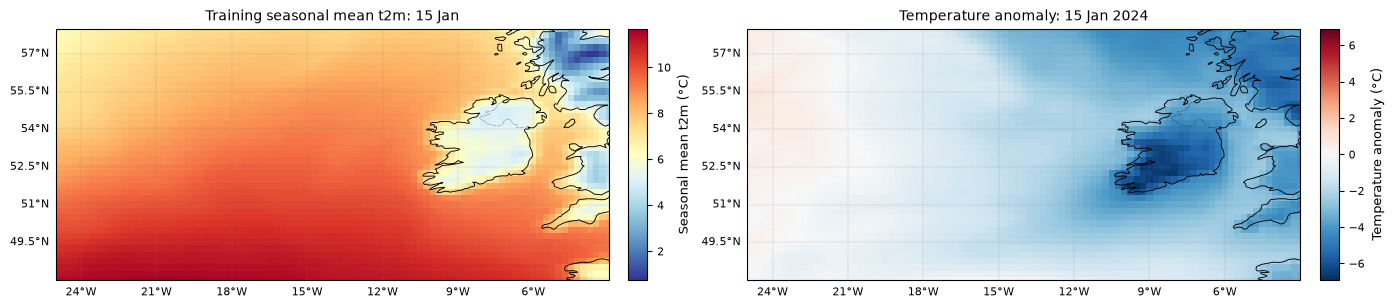

Reference years: [2018, 2019, 2020, 2021, 2022] date: 2024-01-15
Observed anomaly min/max (°C): -6.90880012512207 0.7906064987182617
Blue = colder than the training seasonal expectation; white = near expectation; red = warmer.


In [111]:
# Code step 10
REFERENCE_EXAMPLE_DATE = pd.Timestamp("2024-01-15")
match = np.flatnonzero(split_dates["test"] == REFERENCE_EXAMPLE_DATE)
if len(match):
    example_i = int(match[0])
else:
    example_i = TEST_INDEX
    if example_i >= len(split_dates["test"]):
        raise IndexError("Fixed example unavailable")
    warnings.warn(
        "2024-01-15 unavailable; using the predeclared fixed TEST_INDEX, not a visually chosen day."
    )
example_date = split_dates["test"][example_i]
reference = seasonal_reference["test"][example_i]
departure = temperature_anomalies["test"][example_i]
limit = max(float(np.abs(departure).max()), 0.5)
fig, axes = map_subplots(1, 2, figsize=(14, 5))
map_plot(
    axes[0],
    reference,
    f"Training seasonal mean t2m: {example_date:%d %b}",
    "Seasonal mean t2m (°C)",
    float(reference.min()),
    float(reference.max()),
    TEMPERATURE_CMAP,
)
map_plot(
    axes[1],
    departure,
    f"Temperature anomaly: {example_date:%d %b %Y}",
    "Temperature anomaly (°C)",
    -limit,
    limit,
    ANOMALY_CMAP,
)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "weather_climatology_anomaly.png", dpi=180, bbox_inches="tight")
plt.show()
print("Reference years:", sorted(TRAIN_YEARS), "date:", example_date.date())
print("Observed anomaly min/max (°C):", float(departure.min()), float(departure.max()))
print(
    "Blue = colder than the training seasonal expectation; white = near expectation; red = warmer."
)


**Figure interpretation:** The left map is a seasonal temperature reference, not the observed temperature on that date. The right map is the physical temperature anomaly. Temperature and anomaly have separate colour scales because they represent different quantities; the anomaly range is symmetric about zero. The existing four-panel preprocessing figure also shows the original and standardized fields.

**Code step 11**

## 8b. Compare preprocessing distributions

**Purpose:** How do seasonal removal and SD scaling alter the distribution?

**Input:** Training temperature, anomalies and standardized anomalies.

**Operation:** Plot full-range histograms with zero reference lines.

**Output:** Three distribution panels.

**Lecture connection:** Standardization changes scale; it does not establish linearity or Gaussianity.

**Expected shapes:** Three flattened training arrays [N_train×H×W].

**Data leakage check:** All three distributions use training only.

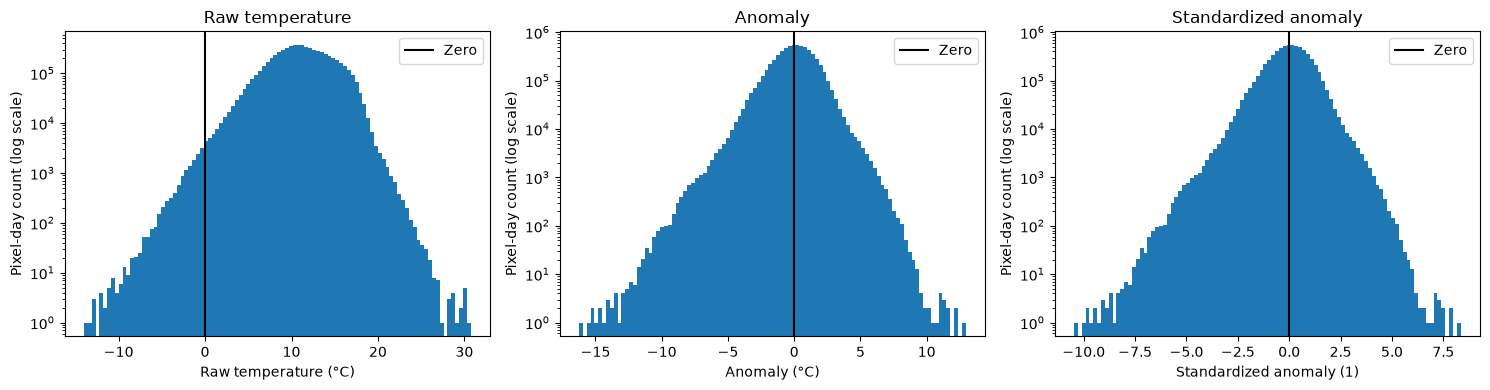

In [112]:
# Code step 11
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, x, title, unit in zip(
    axes,
    [
        temperature_maps["train"],
        temperature_anomalies["train"],
        standardized_anomalies["train"],
    ],
    ["Raw temperature", "Anomaly", "Standardized anomaly"],
    ["°C", "°C", "1"],
):
    ax.hist(x.ravel(), bins=100, log=True)
    ax.axvline(0, color="black", label="Zero")
    ax.set(title=title, xlabel=f"{title} ({unit})", ylabel="Pixel-day count (log scale)")
    ax.legend()
plt.tight_layout()
plt.show()


**Figure interpretation:** Climatology is seasonal expected temperature; anomalies can be positive or negative. SD scaling changes magnitudes and units without proving Gaussianity or linearity. Raw and background maps have individual colourbars; reconstructed physical maps later share a scale.

**Code step 12**

## 9. Reproducible rectangular missing regions

**Purpose:** Can every method see exactly the same cells?

**Input:** Grid and fixed seeds; existing two-rectangle framework.

**Operation:** Size fractions set before evaluation; draw three fixed masks per gap size/day for validation and test.

**Output:** Persisted mask banks; True means hidden.

**Lecture connection:** Denoising/masked reconstruction prevents trivial copying.

**Expected shapes:** Masks [N,H,W]; neural inputs [B,2,H,W].

**Data leakage check:** Masks independent of temperature values; identical for all k and methods.

In [113]:
# Code step 12
if min(map_height, map_width) < 8:
    raise ValueError("Grid too small for this predeclared mask protocol")


def bounds(n, lo, hi):
    return (max(1, int(n * lo)), max(1, int(n * hi)))


GAP_SIZES = {
    name: (*bounds(map_height, *frac), *bounds(map_width, *frac))
    for name, frac in [("small", (0.15, 0.22)), ("large", (0.25, 0.34))]
}


def make_masks(count, map_height, map_width, spec, rng):
    min_h, max_h, min_w, max_w = spec
    if max_h > map_height or max_w > map_width:
        raise ValueError("Mask sizes exceed map size; choose a protocol before testing.")
    masks = np.zeros((count, map_height, map_width), dtype=bool)
    for i in range(count):
        for _ in range(2):
            h = int(rng.integers(min_h, max_h + 1))
            w = int(rng.integers(min_w, max_w + 1))
            top, left = (
                int(rng.integers(map_height - h + 1)),
                int(rng.integers(map_width - w + 1)),
            )
            masks[i, top : top + h, left : left + w] = True
    if np.any(masks.all(axis=(1, 2))):
        raise ValueError("At least one visible cell is required.")
    return masks


def mask_bank(count, base_seed):
    return {
        (size, draw): make_masks(
            count,
            map_height,
            map_width,
            spec,
            np.random.default_rng(base_seed + 100 * j + draw),
        )
        for j, (size, spec) in enumerate(GAP_SIZES.items())
        for draw in range(MASK_DRAWS)
    }


validation_mask_bank = mask_bank(len(standardized_anomalies["validation"]), MASK_SEED)
test_mask_bank = mask_bank(len(standardized_anomalies["test"]), MASK_SEED + 1000)
for split, bank in [("validation", validation_mask_bank), ("test", test_mask_bank)]:
    np.savez_compressed(
        OUTPUT_DIR / f"{split}_masks.npz",
        **{f"{size}_{draw}": a for (size, draw), a in bank.items()},
    )
    for key, m in bank.items():
        print(split, key, "hidden fraction", float(m.mean()))
print("Shared fixed mask banks generated.")


validation ('small', 0) hidden fraction 0.06371646200685495
validation ('small', 1) hidden fraction 0.0641842201090935
validation ('small', 2) hidden fraction 0.06329525447016822
validation ('large', 0) hidden fraction 0.15397050045612046
validation ('large', 1) hidden fraction 0.15651201117213573
validation ('large', 2) hidden fraction 0.15477462393524966
test ('small', 0) hidden fraction 0.06354911219032985
test ('small', 1) hidden fraction 0.06507584232224713
test ('small', 2) hidden fraction 0.06465279056916559
test ('large', 0) hidden fraction 0.15432628446748642
test ('large', 1) hidden fraction 0.1529822527917672
test ('large', 2) hidden fraction 0.15581707391949587
Shared fixed mask banks generated.


**Code step 13**

## 10. Four-neighbour harmonic interpolation baseline

**Purpose:** What can visible neighbours alone reconstruct?

**Input:** One physical map with NaN at hidden cells and its mask.

**Operation:** Iterative four-neighbour averaging with fixed observed cells, edge boundary handling and residual stopping.

**Output:** Completed physical map, iterations, convergence and residual in °C.

**Lecture connection:** A gap-filling baseline; it is not a dimensionality-reduction model.

**Expected shapes:** Input/output [H,W].

**Data leakage check:** Never pass hidden truth to interpolation.

In [114]:
# Code step 13
def neighbor_mean(field):
    p = np.pad(field, 1, mode="edge")
    return (p[:-2, 1:-1] + p[2:, 1:-1] + p[1:-1, :-2] + p[1:-1, 2:]) * 0.25


def harmonic_inpaint(observed, mask, tol=INTERPOLATION_TOL, max_iter=INTERPOLATION_MAX_ITER):
    observed = np.asarray(observed, dtype=np.float64)
    mask = np.asarray(mask, dtype=bool)
    if observed.shape != mask.shape or observed.ndim != 2:
        raise ValueError("Expected matching 2D map and mask")
    if not np.isfinite(observed[~mask]).all() or mask.all():
        raise ValueError("Visible cells must be finite, with at least one visible cell")
    if not mask.any():
        return (observed.copy(), {"iterations": 0, "converged": True, "residual_C": 0.0})
    filled = observed.copy()
    filled[mask] = observed[~mask].mean()
    converged = False
    for iteration in range(1, max_iter + 1):
        filled[mask] = neighbor_mean(filled)[mask]
        residual = float(np.max(np.abs(neighbor_mean(filled)[mask] - filled[mask])))
        if residual <= tol:
            converged = True
            break
    return (
        filled.astype(np.float32),
        {"iterations": iteration, "converged": converged, "residual_C": residual},
    )


print("Harmonic solver defined; tolerance in °C; no hidden truth accepted.")


Harmonic solver defined; tolerance in °C; no hidden truth accepted.


**Code step 14**

## 10b. Validation reference scores for every k

**Purpose:** What error must each ConvAE improve upon?

**Input:** Physical validation targets, shared fixed validation masks, training seasonal reference and training anomaly SD.

**Operation:** Evaluate visible-only harmonic interpolation and seasonal-reference filling. Convert their physical hidden-cell MSE to standardized-anomaly MSE.

**Output:** A pooled validation reference table, convergence records and two scalar reference-line values; EOF references are evaluated in the following cells.

**Lecture connection:** Compare learned masked reconstruction against a non-neural baseline and a seasonal expectation.

**Expected shapes:** Each field/mask [H,W]; two reference scores pooled over every validation pixel–draw observation.

**Data leakage check:** No test data. The seasonal reference and scale are training-only. Hidden targets enter scoring, never the interpolation input.

In [115]:
# Code step 14
reference_cases = []
for (gap_size, mask_draw), masks in validation_mask_bank.items():
    for day_index, hidden_mask in enumerate(masks):
        target = temperature_maps["validation"][day_index]
        # Interpolation receives visible physical temperatures only.
        observed = target.copy()
        observed[hidden_mask] = np.nan
        interpolated, solver_info = harmonic_inpaint(observed, hidden_mask)
        reference_predictions = {
            "Interpolation": interpolated,
            "Seasonal climatology": seasonal_reference["validation"][day_index],
        }
        for method, prediction in reference_predictions.items():
            hidden_error = (prediction[hidden_mask] - target[hidden_mask]).astype("float64")
            reference_cases.append(
                {
                    "method": method,
                    "gap": gap_size,
                    "draw": mask_draw,
                    "index": day_index,
                    "n": len(hidden_error),
                    "squared_error_C": float(hidden_error @ hidden_error),
                    "absolute_error_C": float(np.abs(hidden_error).sum()),
                    "converged": (
                        solver_info["converged"] if method == "Interpolation" else True
                    ),
                    "residual_C": (
                        solver_info["residual_C"] if method == "Interpolation" else np.nan
                    ),
                }
            )
reference_case_table = pd.DataFrame(reference_cases)
# Pool errors by pixel count rather than averaging daily RMSE values.
validation_reference_scores = reference_case_table.groupby("method", as_index=False).agg(
    n=("n", "sum"),
    squared_error_C=("squared_error_C", "sum"),
    absolute_error_C=("absolute_error_C", "sum"),
)
validation_reference_scores["RMSE_C"] = np.sqrt(
    validation_reference_scores.squared_error_C / validation_reference_scores.n
)
validation_reference_scores["MAE_C"] = (
    validation_reference_scores.absolute_error_C / validation_reference_scores.n
)
# Curves use standardized anomalies, so express physical baseline MSE on that SAME scale.
validation_reference_scores["standardized_MSE"] = (
    validation_reference_scores.squared_error_C
    / validation_reference_scores.n
    / training_anomaly_std**2
)
interpolation_validation_mse = float(
    validation_reference_scores.set_index("method").loc["Interpolation", "standardized_MSE"]
)
climatology_validation_mse = float(
    validation_reference_scores.set_index("method").loc[
        "Seasonal climatology", "standardized_MSE"
    ]
)
reference_case_table.to_csv(OUTPUT_DIR / "validation_reference_cases.csv", index=False)
validation_reference_scores.to_csv(OUTPUT_DIR / "validation_reference_scores.csv", index=False)
display(validation_reference_scores)
interpolation_converged = reference_case_table.loc[
    reference_case_table.method == "Interpolation", "converged"
].all()
if not interpolation_converged:
    warnings.warn(
        "Some validation interpolation solves did not converge. Reference lines are provisional; inspect validation_reference_cases.csv."
    )
print(
    "Reference lines use validation masks only, pooled across both gap sizes and all fixed draws."
)
print(
    "Interpolation is the main baseline; seasonal climatology is an additional train-only reference."
)


,method,n,squared_error_C,absolute_error_C,RMSE_C,MAE_C,standardized_MSE
0,Interpolation,874320,1.534813e+05,1.942492e+05,0.418979,0.222172,0.072974
1,Seasonal climatology,874320,2.346440e+06,1.141108e+06,1.638210,1.305137,1.115639


Reference lines use validation masks only, pooled across both gap sizes and all fixed draws.
Interpolation is the main baseline; seasonal climatology is an additional train-only reference.


**Figure interpretation:** Interpolation uses visible neighbours. Seasonal climatology fills each hidden cell with its training-derived seasonal expectation, without using visible temperatures. Neither baseline learns over epochs or changes with k. These are validation references, not test results.

**Code step 15**

# 10c. Experiment A — PCA/EOF: learn patterns and fill from visible cells

**Purpose:** Can a linear learned spatial representation fill the same gaps?

**Input:** Complete training standardized-anomaly maps; ConvAE k candidates and fixed ridge strength.

**Operation:** Flatten training maps, fit centered PCA/EOFs, then infer incomplete-map coefficients using only visible cells.

**Output:** Training-fitted EOF mean/basis, feasible k values, eof_fill helper and saved basis archive.

**Lecture connection:** A linear k-mode reconstruction baseline; this is not the iterative DINEOF algorithm.

**Expected shapes:** Training matrix [N_train,H×W]; basis [max_k,H×W]; visible design [N_visible,k]; reconstructed field [H,W].

**Data leakage check:** Mean/basis fit training only. The inference function never reads hidden inputs or updates the basis from validation/test.

Further reading: [Beckers & Rixen (2003), EOF calculations and data filling](https://orbi.uliege.be/handle/2268/4291). Their missing-data reconstruction research motivates EOF baselines; this notebook uses a fixed training-fitted EOF basis and visible-cell coefficient inference, not a reproduction of DINEOF.

In [116]:
# Code step 15
training_matrix = standardized_anomalies["train"].reshape(
    len(standardized_anomalies["train"]), -1
)
maximum_rank = min(len(training_matrix) - 1, training_matrix.shape[1])
EOF_K_VALUES = [k for k in CONV_LATENT_DIMS if k <= maximum_rank]
if not EOF_K_VALUES:
    raise ValueError(
        "Training rank cannot support the requested EOF dimensions; revise the candidate protocol before evaluating test data."
    )
if EOF_K_VALUES != CONV_LATENT_DIMS:
    warnings.warn(
        f"EOF comparison limited by training rank: feasible k={EOF_K_VALUES}. Equal-k plots omit unavailable EOF values."
    )
# Exact SVD is deterministic but may take time for the complete archive.
eof_model = PCA(n_components=max(EOF_K_VALUES), svd_solver="full")
eof_model.fit(training_matrix)
eof_mean = eof_model.mean_.astype("float64")
eof_patterns = eof_model.components_.astype("float64")


def eof_fill(observed_anomaly, hidden_mask, k):
    """Infer a fixed training-EOF mixture from visible standardized anomalies only."""
    if observed_anomaly.shape != hidden_mask.shape or observed_anomaly.shape != (
        map_height,
        map_width,
    ):
        raise ValueError("EOF input and mask must match the map grid")
    if k not in EOF_K_VALUES:
        raise ValueError(f"Unsupported EOF k={k}")
    visible = (~hidden_mask).ravel()
    if not visible.any():
        raise ValueError("At least one visible cell is required")
    observed_values = observed_anomaly.ravel()[visible].astype("float64")
    if not np.isfinite(observed_values).all():
        raise ValueError("Visible EOF inputs must be finite")
    # Do NOT use eof_model.transform on a complete held-out target.
    basis = eof_patterns[:k].T
    visible_basis = basis[visible]
    centered_visible = observed_values - eof_mean[visible]
    coefficients = np.linalg.solve(
        visible_basis.T @ visible_basis + EOF_RIDGE * np.eye(k),
        visible_basis.T @ centered_visible,
    )
    reconstructed = eof_mean + basis @ coefficients
    return reconstructed.reshape(map_height, map_width).astype("float32")


np.savez_compressed(
    OUTPUT_DIR / "training_eof_basis.npz",
    mean=eof_mean,
    patterns=eof_patterns,
    explained_variance_ratio=eof_model.explained_variance_ratio_,
    k_values=EOF_K_VALUES,
)
print("Training-only EOF basis:", eof_patterns.shape, "; feasible components k:", EOF_K_VALUES)
print("Inference uses visible cells only; equal grid-cell weights, fixed ridge:", EOF_RIDGE)


Training-only EOF basis: (128, 3649) ; feasible components k: [8, 16, 32, 64, 128]
Inference uses visible cells only; equal grid-cell weights, fixed ridge: 1e-06


**Figure interpretation:** EOF k counts linear spatial patterns; ConvAE k counts latent values per map. Matching k matches representation width, not parameter count, compute or inference procedure. No claim of physical linearity follows from a good EOF result.

**Code step 16**

## 10d. Experiment A — PCA/EOF: evaluate every k on validation

**Purpose:** Which EOF k gives the lowest validation hidden-cell error?

**Input:** Frozen training EOF basis; same fixed validation mask bank used by neural validation.

**Operation:** Infer visible-only coefficients for each k. Pool physical hidden-cell errors, report both gap sizes and select k from pooled validation RMSE.

**Output:** Validation EOF case table, by-k/by-gap metrics, standardized MSE references and selected_eof_k.

**Lecture connection:** Held-out selection of linear representation width, independently of ConvAE k.

**Expected shapes:** One row per k/gap/draw/day; selected k is a scalar.

**Data leakage check:** Validation selects EOF k; test remains untouched. Hidden truth is used only to score predictions.

In [117]:
# Code step 16
eof_reference_cases = []
for (gap_size, mask_draw), masks in validation_mask_bank.items():
    for day_index, hidden_mask in enumerate(masks):
        observed = standardized_anomalies["validation"][day_index].copy()
        observed[hidden_mask] = np.nan
        for k in EOF_K_VALUES:
            predicted_anomaly = eof_fill(observed, hidden_mask, k)
            predicted_temperature = (
                predicted_anomaly * training_anomaly_std
                + seasonal_reference["validation"][day_index]
            )
            hidden_error = (
                predicted_temperature[hidden_mask]
                - temperature_maps["validation"][day_index][hidden_mask]
            ).astype("float64")
            eof_reference_cases.append(
                dict(
                    k=k,
                    gap=gap_size,
                    draw=mask_draw,
                    index=day_index,
                    n=len(hidden_error),
                    se=float(hidden_error @ hidden_error),
                    ae=float(np.abs(hidden_error).sum()),
                )
            )
eof_validation_cases = pd.DataFrame(eof_reference_cases)


def summarize_eof_validation(keys):
    table = eof_validation_cases.groupby(keys, as_index=False).agg(
        n=("n", "sum"), se=("se", "sum"), ae=("ae", "sum")
    )
    table["RMSE_C"] = np.sqrt(table.se / table.n)
    table["MAE_C"] = table.ae / table.n
    table["standardized_MSE"] = table.se / table.n / training_anomaly_std**2
    return table


eof_validation_by_k = summarize_eof_validation(["k"]).sort_values("k")
eof_validation_by_gap = summarize_eof_validation(["k", "gap"])
selected_eof_k = int(eof_validation_by_k.sort_values(["RMSE_C", "k"]).iloc[0].k)
eof_mse_by_k = eof_validation_by_k.set_index("k").standardized_MSE.to_dict()
eof_validation_cases.to_csv(OUTPUT_DIR / "eof_validation_cases.csv", index=False)
eof_validation_by_k.to_csv(OUTPUT_DIR / "eof_k_validation.csv", index=False)
eof_validation_by_gap.to_csv(OUTPUT_DIR / "eof_k_validation_by_gap.csv", index=False)
display(eof_validation_by_k)
display(eof_validation_by_gap)
print("Validation-selected EOF k:", selected_eof_k, "; test data have not been used.")


,k,n,se,ae,RMSE_C,MAE_C,standardized_MSE
0,8,874320,151122.348746,260149.639714,0.415747,0.297545,0.071853
1,16,874320,87145.868322,195991.927086,0.315710,0.224165,0.041434
2,32,874320,64371.027582,161971.084259,0.271338,0.185254,0.030606
3,64,874320,64611.811637,152416.560099,0.271845,0.174326,0.030720
4,128,874320,67315.181798,154986.601379,0.277473,0.177265,0.032006


,k,gap,n,se,ae,RMSE_C,MAE_C,standardized_MSE
0,8,large,619669,112545.648748,189073.656769,0.426172,0.305120,0.075501
1,8,small,254651,38576.699998,71075.982945,0.389215,0.279111,0.062974
2,16,large,619669,65738.799455,143691.245198,0.325710,0.231884,0.044101
3,16,small,254651,21407.068866,52300.681888,0.289939,0.205382,0.034946
4,32,large,619669,50536.549441,120505.865550,0.285577,0.194468,0.033902
5,32,small,254651,13834.478140,41465.218709,0.233082,0.162832,0.022584
6,64,large,619669,54838.791883,117549.139411,0.297484,0.189697,0.036789
7,64,small,254651,9773.019754,34867.420689,0.195903,0.136922,0.015954
8,128,large,619669,58052.052113,122189.922348,0.306076,0.197186,0.038944
9,128,small,254651,9263.129685,32796.679031,0.190724,0.128791,0.015122


Validation-selected EOF k: 32 ; test data have not been used.


**Code step 17**

## PCA/EOF experiment: choose k on validation

**Purpose:** Which EOF k fills validation gaps best, compared with interpolation?

**Input:** `eof_validation_by_k`, `eof_validation_by_gap`, training SD and interpolation validation scores.

**Operation:** Plot all feasible k, pooled across the identical fixed validation masks. Draw interpolation as a horizontal reference.

**Output:** Saved PCA/EOF validation chart and selected-k table. No test selection.

**Lecture connection:** Linear representation capacity; validation-based model selection.

**Expected shapes:** One row per k; maps remain [H,W].

**Data leakage check:** EOF basis uses training only; k selection uses validation only.


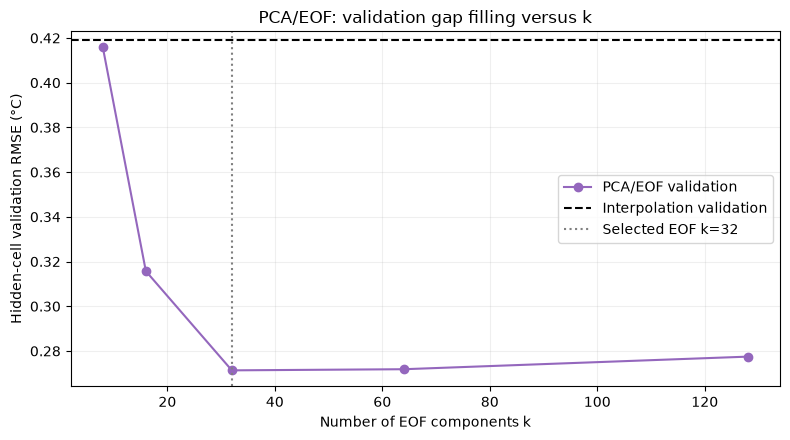

,k,RMSE_C,MAE_C
0,8,0.415747,0.297545
1,16,0.315710,0.224165
2,32,0.271338,0.185254
3,64,0.271845,0.174326
4,128,0.277473,0.177265


In [118]:
# Code step 17
interpolation_validation_rmse = float(validation_reference_scores.set_index("method").loc["Interpolation", "RMSE_C"])
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(eof_validation_by_k.k, eof_validation_by_k.RMSE_C, "o-", color="tab:purple", label="PCA/EOF validation")
ax.axhline(interpolation_validation_rmse, color="black", linestyle="--", label="Interpolation validation")
ax.axvline(selected_eof_k, color="gray", linestyle=":", label=f"Selected EOF k={selected_eof_k}")
ax.set(title="PCA/EOF: validation gap filling versus k", xlabel="Number of EOF components k", ylabel="Hidden-cell validation RMSE (°C)")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "eof_validation_k_vs_interpolation.png", dpi=160)
plt.show()
display(eof_validation_by_k[["k", "RMSE_C", "MAE_C"]])

**Figure interpretation:** Choose k using the lowest validation RMSE. A lower MAE at a different k does not change this predeclared RMSE selection rule. Interpolation has no k.


**Figure interpretation:** A smaller EOF k with lower held-out error is a legitimate result. Each method selects its own k from validation; the final selected-method test comparison may therefore use different k values. Side-by-side ConvAE panels separately compare the two models at the same k.

**Code step 18**

## 11. Shared device and reproducibility setup; Experiment B — ConvAE

**Purpose:** How is the convolutional gap-filling model defined?

**Input:** Grid shape, candidate latent widths and device availability.

**Operation:** Define two-channel spatial encoder/decoder; pad bottom/right and crop back to the same grid.

**Output:** ConvAE class, available device and software version.

**Lecture connection:** Masked/denoising reconstruction with a learned nonlinear encoder/decoder.

**Expected shapes:** [B,2,H,W] → internal feature maps/vector → [B,H,W].

**Data leakage check:** Fixed settings; no fitting or test-based architecture selection.

In [119]:
# Code step 18
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

# CPU is the default after repeated XPU validation changed for identical inputs.
# Train and evaluate on the SAME backend. Do not reuse earlier XPU results.
DEVICE_OVERRIDE = "cuda"
if DEVICE_OVERRIDE:
    device = torch.device(DEVICE_OVERRIDE)
elif hasattr(torch, "xpu") and torch.xpu.is_available():
    device = torch.device("xpu")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if hasattr(torch, "xpu") and torch.xpu.is_available():
        torch.xpu.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True, warn_only=False)


class ConvAE(nn.Module):
    """Fill a masked map through a convolutional encoder and a k-value latent code."""

    def __init__(self, map_height, map_width, latent_dim):
        super().__init__()
        self.map_height = map_height
        self.map_width = map_width
        self.latent_dim = latent_dim
        self.padded_height = 4 * math.ceil(map_height / 4)
        self.padded_width = 4 * math.ceil(map_width / 4)
        self.feature_shape = (32, self.padded_height // 4, self.padded_width // 4)
        feature_count = math.prod(self.feature_shape)
        self.encoder1 = nn.Sequential(nn.Conv2d(2, 16, 3, stride=2, padding=1), nn.ReLU())
        self.encoder2 = nn.Sequential(nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU())
        self.to_latent = nn.Linear(feature_count, latent_dim)
        self.from_latent = nn.Linear(latent_dim, feature_count)
        self.decoder1 = nn.Sequential(nn.Conv2d(32, 16, 3, padding=1), nn.ReLU())
        self.output_layer = nn.Conv2d(16, 1, 3, padding=1)

    def encode(self, temperature_batch, hidden_mask, trace=False):
        pad = (0, self.padded_width - self.map_width, 0, self.padded_height - self.map_height)
        # Remove hidden truth before the encoder sees the map.
        visible_values = temperature_batch.masked_fill(hidden_mask, 0)
        values = F.pad(visible_values.unsqueeze(1), pad)
        # A separate channel distinguishes hidden cells from real zero anomalies.
        mask_channel = F.pad(hidden_mask.unsqueeze(1).float(), pad, value=1)
        encoder_input = torch.cat([values, mask_channel], dim=1)
        features1 = self.encoder1(encoder_input)
        features2 = self.encoder2(features1)
        # k is the number of values describing one map.
        latent_code = self.to_latent(features2.flatten(1))
        if trace:
            print("Two-channel padded input:", tuple(encoder_input.shape))
            print("Encoder 1 / encoder 2:", tuple(features1.shape), tuple(features2.shape))
            print("Latent code z:", tuple(latent_code.shape))
        return latent_code

    def decode(self, latent_code, trace=False):
        features = F.relu(self.from_latent(latent_code))
        features = features.reshape(-1, *self.feature_shape)
        features = F.interpolate(features, scale_factor=2, mode="nearest")
        features = self.decoder1(features)
        features = F.interpolate(features, scale_factor=2, mode="nearest")
        padded_prediction = self.output_layer(features)
        # Crop only bottom/right padding to preserve geographic alignment.
        prediction = padded_prediction[:, 0, : self.map_height, : self.map_width]
        if trace:
            print("Padded decoder output:", tuple(padded_prediction.shape))
            print("Cropped reconstructed map:", tuple(prediction.shape))
        return prediction

    def forward(self, temperature_batch, hidden_mask, trace=False):
        if temperature_batch.ndim != 3 or temperature_batch.shape != hidden_mask.shape:
            raise ValueError("Expected matching map and mask batches [B,H,W]")
        if temperature_batch.shape[-2:] != (self.map_height, self.map_width):
            raise ValueError("Input does not match the declared grid")
        latent_code = self.encode(temperature_batch, hidden_mask, trace)
        return self.decode(latent_code, trace)


print("ConvAE ready: encode(masked map, mask) → latent code → decode(code).")

print("Compute device:", device, "; PyTorch:", torch.__version__)
if device.type == "cuda":
    print("CUDA device:", torch.cuda.get_device_name(device))

print("CPU reference run: all neural models must be retrained from scratch.")


ConvAE ready: encode(masked map, mask) → latent code → decode(code).
Compute device: cuda ; PyTorch: 2.11.0+cu128
CUDA device: NVIDIA GeForce RTX 5060 Laptop GPU
CPU reference run: all neural models must be retrained from scratch.


**Code step 19**

# 12. Experiment B — verify ConvAE tensor shapes

**Purpose:** Does the decoder preserve odd grid dimensions?

**Input:** A dummy batch and all declared ConvAE latent widths.

**Operation:** Trace stages; assert output shape; report parameter count and padding fraction.

**Output:** Architecture table and tensor trace.

**Lecture connection:** Encoder → code → decoder, used here solely for gap filling.

**Expected shapes:** Dummy input/output [2,H,W].

**Data leakage check:** No real data or model training.
**Backend decision:** this revision defaults to CPU because the user measured different repeated XPU validation losses for identical saved weights and fixed masks. CPU repeated evaluation was stable in that diagnostic. The underlying XPU cause is unconfirmed. Full CPU training and validation must pass the existing integrity checks before scientific comparisons.


In [120]:
# Code step 19
set_seed(SEED)
architecture_rows = []
for latent_dim in CONV_LATENT_DIMS:
    if latent_dim < 1:
        raise ValueError("Latent dimensions must be positive")
    model = ConvAE(map_height, map_width, latent_dim)
    with torch.no_grad():
        probe = torch.zeros(2, map_height, map_width)
        probe_mask = torch.zeros_like(probe, dtype=torch.bool)
        reconstruction = model(probe, probe_mask, trace=latent_dim == CONV_LATENT_DIMS[0])
    assert reconstruction.shape == probe.shape
    architecture_rows.append(
        {"latent_dim": latent_dim, "parameters": sum((p.numel() for p in model.parameters()))}
    )
    padding_fraction = (model.padded_height * model.padded_width - map_height * map_width) / (
        map_height * map_width
    )
    del model
architecture_table = pd.DataFrame(architecture_rows)
display(architecture_table)
print("Output shapes verified for every k. Extra padded-cell fraction:", padding_fraction)
if padding_fraction > 0.25:
    warnings.warn("Substantial padding; inspect grid alignment.")


Two-channel padded input: (2, 2, 44, 92)
Encoder 1 / encoder 2: (2, 16, 22, 46) (2, 32, 11, 23)
Latent code z: (2, 8)
Padded decoder output: (2, 1, 44, 92)
Cropped reconstructed map: (2, 41, 89)


,latent_dim,parameters
0,8,147353
1,16,276897
2,32,535985
3,64,1054161
4,128,2090513


Output shapes verified for every k. Extra padded-cell fraction: 0.10934502603453


**Code step 20**

## 13a. Name runs and build models

**Purpose:** How are different k runs kept separate?

**Input:** Model name and optional ConvAE latent dimension.

**Operation:** Generate a unique run label and construct the corresponding architecture.

**Output:** Model factory; run_name gives ConvAE_k8, ConvAE_k16, etc.

**Lecture connection:** Architecture definitions, not training.

**Expected shapes:** Each model predicts [B,H,W].

**Data leakage check:** No fitting or held-out values.

In [121]:
# Code step 20
def run_name(model_name, latent_dim=None):
    """Keep each k's checkpoint and history separate."""
    if model_name == "ConvAE":
        if latent_dim is None:
            raise ValueError("ConvAE needs an explicit latent_dim")
        return f"ConvAE_k{latent_dim}"
    return model_name


def build_model(model_name, latent_dim=None):
    if model_name == "ConvAE":
        return ConvAE(map_height, map_width, latent_dim)
    if model_name == "Spatial Transformer":
        return ERA5Transformer(map_height, map_width, **TRANSFORMER_CONFIG)
    raise ValueError(f"Unknown model: {model_name}")


print("Ready: Name runs and build models.")


Ready: Name runs and build models.


**Code step 21**

## 13b. Measure fixed-mask validation loss

**Purpose:** How is validation evaluated without updating weights?

**Input:** Frozen validation targets and identical validation masks for every run.

**Operation:** Disable gradients; pool squared errors only over hidden cells.

**Output:** One validation MSE scalar.

**Lecture connection:** Held-out reconstruction.

**Expected shapes:** Target/mask/prediction [B,H,W].

**Data leakage check:** Validation does not update weights or scaling.

In [122]:
# Code step 21
@torch.no_grad()
def validation_loss(model):
    """Evaluate all fixed validation gaps without changing model weights."""
    model.eval()
    total_squared_error = 0.0
    hidden_pixel_count = 0
    for mask_array in validation_mask_bank.values():
        for start in range(0, len(standardized_anomalies["validation"]), BATCH_SIZE):
            target_batch = torch.as_tensor(
                standardized_anomalies["validation"][start : start + BATCH_SIZE], device=device
            )
            hidden_mask = torch.as_tensor(
                mask_array[start : start + len(target_batch)], device=device
            )
            # Hidden targets are retained for the loss, but excluded from the input.
            masked_input = target_batch.masked_fill(hidden_mask, 0)
            prediction = model(masked_input, hidden_mask)
            # Score deliberately hidden pixels only.
            hidden_error = (prediction.double() - target_batch.double())[hidden_mask]
            total_squared_error += float(hidden_error.square().sum())
            hidden_pixel_count += hidden_error.numel()
    return total_squared_error / hidden_pixel_count


print("Ready: Measure fixed-mask validation loss.")


Ready: Measure fixed-mask validation loss.


**Code step 22**

## Fingerprint this experiment before saving weights

**Purpose:** Can a checkpoint be matched to the exact training preprocessing and validation masks?

**Input:** Training and validation standardized maps, dates, grids, climatology and validation masks.

**Operation:** Compute a SHA-256 fingerprint once. Include it in every new checkpoint.

**Output:** `EXPERIMENT_FINGERPRINT` for stale-state checks.

**Lecture connection:** Reproducibility and separation of model fitting from testing.

**Expected shapes:** Maps [N,H,W], validation masks [N,H,W], one hash string.

**Data leakage check:** Test targets are excluded from this identifier.


In [123]:
# Code step 22
def update_array_hash(hasher, array):
    a = np.ascontiguousarray(array)
    hasher.update(str(a.shape).encode("utf-8"))
    hasher.update(str(a.dtype).encode("utf-8"))
    hasher.update(a.tobytes())

hasher = hashlib.sha256()
for split in ["train", "validation"]:
    update_array_hash(hasher, standardized_anomalies[split])
    hasher.update("|".join(str(t) for t in split_dates[split]).encode("utf-8"))
for key, masks in sorted(validation_mask_bank.items()):
    hasher.update(str(key).encode("utf-8"))
    update_array_hash(hasher, masks)
update_array_hash(hasher, climatology)
update_array_hash(hasher, latitude)
update_array_hash(hasher, longitude)
hasher.update(str(training_anomaly_std).encode("utf-8"))
EXPERIMENT_FINGERPRINT = hasher.hexdigest()
print("Training/preprocessing/validation fingerprint:", EXPERIMENT_FINGERPRINT[:16])
print("Test targets are excluded from this checkpoint fingerprint.")

Training/preprocessing/validation fingerprint: 5bf930b2860808b6
Test targets are excluded from this checkpoint fingerprint.


**Code step 23**

## 13c. Train one model and save its best epoch

**Purpose:** What happens during one independent model fit?

**Input:** Training standardized anomalies, architecture and predeclared settings.

**Operation:** Build batches, draw gaps, compute hidden-cell MSE, update weights, validate and save the best epoch.

**Output:** Checkpoint and complete epoch history for this run.

**Lecture connection:** Reconstruction learning and validation early stopping.

**Expected shapes:** Batches [B,H,W]; loss scalar.

**Data leakage check:** Training updates only; validation chooses epoch; no test access.
**Windows checkpoint safeguard:** write through a binary stream to a temporary file, then rename to a new unique checkpoint filename. Close read streams explicitly and disable memory mapping. A small save/load preflight runs before training. Locked obsolete files are retained with a warning. Model selection, masks and validation-integrity checks remain unchanged.


In [124]:
# Code step 23
# Explicit file streams avoid the PyTorch filename-writer path on Windows.
import os
import tempfile
import uuid


def load_checkpoint_file(path):
    # Close the stream immediately; do not memory-map the checkpoint file.
    with Path(path).open("rb") as stream:
        return torch.load(stream, map_location="cpu", weights_only=True, mmap=False)


def save_checkpoint_file(payload, base_path, previous_path=None):
    """Write a new best checkpoint without overwriting a possibly mapped file."""
    base_path = Path(base_path)
    base_path.parent.mkdir(parents=True, exist_ok=True)
    epoch = int(payload.get("best_epoch", 0))
    unique = uuid.uuid4().hex[:12]
    destination = base_path.with_name(f"{base_path.stem}_epoch{epoch:03d}_{unique}.pt")
    temporary_path = None
    try:
        # The temporary file is on the same filesystem as its final destination.
        with tempfile.NamedTemporaryFile(mode="wb", prefix="checkpoint_", suffix=".tmp",
                                         dir=base_path.parent, delete=False) as stream:
            temporary_path = Path(stream.name)
            torch.save(payload, stream)
            stream.flush()
            os.fsync(stream.fileno())
        # Destination is new and unique: no old checkpoint must be overwritten.
        os.replace(temporary_path, destination)
    except (OSError, RuntimeError) as exc:
        if temporary_path is not None:
            try:
                temporary_path.unlink(missing_ok=True)
            except OSError:
                pass
        raise RuntimeError(
            f"Checkpoint write failed in {base_path.parent.resolve()}. "
            "Close checkpoint previews/other training processes and verify a writable local disk "
            "with free space. Original exception is chained below."
        ) from exc
    # Remove only an older uniquely named checkpoint from this training run.
    if previous_path is not None:
        old = Path(previous_path)
        if old != base_path and old != destination and old.parent == destination.parent:
            try:
                old.unlink(missing_ok=True)
            except OSError as exc:
                warnings.warn(f"Previous checkpoint is locked; kept {old.name}: {exc}")
    return destination


# Fail early on a filesystem problem, before spending time on training.
probe_path = save_checkpoint_file({"probe": torch.zeros(2), "best_epoch": 0},
                                  OUTPUT_DIR / "checkpoint_write_probe.pt")
probe_payload = load_checkpoint_file(probe_path)
assert torch.equal(probe_payload["probe"], torch.zeros(2))
del probe_payload
try:
    probe_path.unlink()
except OSError as exc:
    warnings.warn(f"Probe file remains locked but save/load succeeded: {exc}")
print("Checkpoint save/load preflight passed:", OUTPUT_DIR.resolve())

checkpoints = {}

histories = {}

training_rows = []


def train_model(model_name, latent_dim=None):
    """Fit one model; the validation bank selects its best epoch."""
    set_seed(SEED)
    label = run_name(model_name, latent_dim)
    model = build_model(model_name, latent_dim).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATES[model_name], weight_decay=1e-05
    )
    train_loader = DataLoader(
        TensorDataset(torch.from_numpy(standardized_anomalies["train"])),
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )
    # Reset this generator for every k so training gaps follow the same sequence.
    mask_generator = np.random.default_rng(SEED + 500)
    history = []
    best_validation_mse = float("inf")
    best_epoch = None
    epochs_without_improvement = 0
    filename = label.lower().replace(" ", "_")
    checkpoint_path = OUTPUT_DIR / f"{filename}_seed{SEED}.pt"
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        total_squared_error = 0.0
        hidden_pixel_count = 0
        for (target_batch,) in train_loader:
            target_batch = target_batch.to(device)
            gap_name = list(GAP_SIZES)[int(mask_generator.integers(len(GAP_SIZES)))]
            mask_array = make_masks(
                len(target_batch), map_height, map_width, GAP_SIZES[gap_name], mask_generator
            )
            hidden_mask = torch.from_numpy(mask_array).to(device)
            # Hidden targets are retained for the loss, but excluded from the input.
            masked_input = target_batch.masked_fill(hidden_mask, 0)
            prediction = model(masked_input, hidden_mask)
            if prediction.shape != target_batch.shape:
                raise ValueError("Prediction and target shapes differ")
            # Score deliberately hidden pixels only.
            hidden_error = (prediction - target_batch)[hidden_mask]
            loss = hidden_error.square().mean()
            if not torch.isfinite(loss):
                raise ValueError("Non-finite training loss")
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_squared_error += float(hidden_error.detach().double().square().sum())
            hidden_pixel_count += hidden_error.numel()
        training_mse = total_squared_error / hidden_pixel_count
        validation_mse = validation_loss(model)
        if not np.isfinite(validation_mse):
            raise ValueError("Non-finite validation loss")
        history.append(
            {"epoch": epoch, "train_mse": training_mse, "validation_mse": validation_mse}
        )
        pd.DataFrame(history).to_csv(OUTPUT_DIR / f"{filename}_history.csv", index=False)
        print(
            f"{label}: epoch {epoch:02d}; training MSE={training_mse:.6f}; validation MSE={validation_mse:.6f}"
        )
        # Select checkpoints using validation only; test data are not consulted.
        if validation_mse < best_validation_mse:
            best_validation_mse = validation_mse
            best_epoch = epoch
            epochs_without_improvement = 0
            state = {
                name: value.detach().cpu().clone() for name, value in model.state_dict().items()
            }
            checkpoint_path = save_checkpoint_file(
                {
                    "experiment_fingerprint": EXPERIMENT_FINGERPRINT,
                    "model_name": model_name,
                    "latent_dim": latent_dim,
                    "state_dict": state,
                    "height": map_height,
                    "width": map_width,
                    "seed": SEED,
                    "transformer_config": TRANSFORMER_CONFIG,
                    "best_validation_mse": best_validation_mse,
                    "best_epoch": best_epoch,
                    "SD_train": training_anomaly_std,
                    "climatology": torch.from_numpy(climatology),
                    "latitude": latitude.tolist(),
                    "longitude": longitude.tolist(),
                    "variable": VARIABLE,
                    "physical_units": "degrees Celsius",
                },
                OUTPUT_DIR / f"{filename}_seed{SEED}.pt",
                previous_path=checkpoint_path,
            )
        else:
            epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            break
    if len(history) == MAX_EPOCHS and best_epoch >= MAX_EPOCHS - PATIENCE:
        warnings.warn(
            f"{label}: validation improved near the epoch budget; convergence is not established."
        )
    # Check the exact saved weights under the SAME batched validation protocol.
    saved = load_checkpoint_file(checkpoint_path)
    if saved["experiment_fingerprint"] != EXPERIMENT_FINGERPRINT:
        raise RuntimeError("Checkpoint fingerprint does not match this run")
    model.load_state_dict(saved["state_dict"])
    reloaded_mse = validation_loss(model)
    agrees = bool(np.isclose(reloaded_mse, best_validation_mse,
                             rtol=CHECKPOINT_RTOL, atol=CHECKPOINT_ATOL))
    validation_integrity_rows.append(dict(
        run=label, check="training_checkpoint_reload", expected_mse=best_validation_mse,
        measured_mse=reloaded_mse, passed=agrees))
    pd.DataFrame(validation_integrity_rows).to_csv(
        OUTPUT_DIR / "validation_integrity.csv", index=False)
    if not agrees:
        raise RuntimeError(
            f"{label}: saved-checkpoint validation mismatch: "
            f"training best={best_validation_mse:.9g}, reload={reloaded_mse:.9g}. "
            "Test evaluation blocked. Inspect validation_integrity.csv. "
            "Restart the kernel and Run All; verify the device/backend if it persists.")
    print(f"{label}: checkpoint reload verified (MSE={reloaded_mse:.6f})")
    checkpoints[label] = checkpoint_path
    histories[label] = history
    training_rows.append(
        {
            "method": model_name,
            "run": label,
            "latent_dim": latent_dim,
            "best_epoch": best_epoch,
            "epochs_run": len(history),
            "best_validation_RMSE_C": math.sqrt(best_validation_mse) * training_anomaly_std,
            "parameters": sum((parameter.numel() for parameter in model.parameters())),
            "learning_rate": LEARNING_RATES[model_name],
        }
    )
    pd.DataFrame(training_rows).to_csv(OUTPUT_DIR / "training_summary.csv", index=False)
    del model, optimizer
    if device.type == "cuda":
        torch.cuda.empty_cache()
    elif device.type == "xpu":
        torch.xpu.empty_cache()


print("Ready: Train one model and save its best epoch.")


Checkpoint save/load preflight passed: S:\git-repo\pgr\py-torch\courses\STAT41140-AI for Weather and Climate\homework3\model\t2m_gapfill_separate\20261020T085548_522148Z
Ready: Train one model and save its best epoch.


**Code step 24**

## 13d. Reload the selected model and predict a map

**Purpose:** How do later cells use the correct saved weights?

**Input:** Validation-selected ConvAE k or Transformer name; one standardized map and mask.

**Operation:** Read that run’s checkpoint; hide unknown cells before inference.

**Output:** Frozen model and one reconstructed standardized map.

**Lecture connection:** Generalization using the selected checkpoint.

**Expected shapes:** Input/output [H,W], temporarily batched to [1,H,W].

**Data leakage check:** k and epochs selected from validation; no test tuning.

In [125]:
# Code step 24
def load_model(model_name, latent_dim=None):
    # Optional k also permits fixed-day maps for every trained ConvAE.
    if model_name == "ConvAE" and latent_dim is None:
        latent_dim = selected_conv_k
    label = run_name(model_name, latent_dim)
    # Reload the selected best-epoch weights, not the last training epoch.
    checkpoint = load_checkpoint_file(checkpoints[label])
    if checkpoint.get("experiment_fingerprint") != EXPERIMENT_FINGERPRINT:
        raise RuntimeError("Stale or incompatible checkpoint; restart and Run All")
    if checkpoint["height"] != map_height or checkpoint["width"] != map_width:
        raise RuntimeError("Checkpoint grid differs from current grid")
    model = build_model(checkpoint["model_name"], checkpoint["latent_dim"])
    model.load_state_dict(checkpoint["state_dict"])
    return model.to(device).eval()


@torch.no_grad()
def neural_predict(model, standardized_map, hidden_mask):
    temperature_batch = torch.as_tensor(standardized_map[None], device=device)
    mask_batch = torch.as_tensor(hidden_mask[None], device=device)
    prediction = model(temperature_batch.masked_fill(mask_batch, 0), mask_batch)
    return prediction[0].cpu().numpy()


print("Ready: Reload the selected model and predict a map.")


Ready: Reload the selected model and predict a map.


**Code step 25**

## 13e. Draw one learning curve

**Purpose:** How are the saved losses displayed?

**Input:** One run’s epoch history.

**Operation:** Plot training and validation loss against epochs, save the figure when called.

**Output:** Reusable plot_learning function.

**Lecture connection:** Optimization versus held-out reconstruction.

**Expected shapes:** Two variable-length [epochs] series.

**Data leakage check:** Plots use training/validation loss only.

In [126]:
# Code step 25
def plot_learning(model_name, latent_dim=None):
    label = run_name(model_name, latent_dim)
    history = pd.DataFrame(histories[label])
    fig, axis = plt.subplots(figsize=(8, 4))
    axis.plot(history.epoch, history.train_mse, label="Training")
    axis.plot(history.epoch, history.validation_mse, label="Validation")
    axis.set(
        title=label + ": hidden-cell reconstruction",
        xlabel="Epoch",
        ylabel="MSE (standardized anomaly²)",
    )
    axis.legend()
    plt.tight_layout()
    fig.savefig(
        OUTPUT_DIR / f"{label.lower().replace(' ', '_')}_learning_curve.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()


print(
    "Training helpers ready: remove hidden values → predict → hidden-cell MSE → validate → save best epoch."
)
print("Ready: Draw one learning curve.")


Training helpers ready: remove hidden values → predict → hidden-cell MSE → validate → save best epoch.
Ready: Draw one learning curve.


**Code step 26**

## 14. Experiment B — train all ConvAE k values and select on validation

**Purpose:** How well does the convolutional model learn to fill training gaps?

**Input:** ConvAE, training maps and validation mask bank.

**Operation:** Train one independent ConvAE per k. Choose the lowest best-validation RMSE; ties favor smaller k.

**Output:** One checkpoint/history per k, validation comparison table and selected_conv_k.

**Lecture connection:** Masked autoencoder reconstruction, not a storage experiment.

**Expected shapes:** Batch [B,H,W]; explicit separate hidden mask.

**Data leakage check:** Training updates only; no test access.

In [127]:
# Code step 26
for latent_dim in CONV_LATENT_DIMS:
    print(f"\nTraining a new ConvAE with k={latent_dim}")
    # Each run starts from new weights and resets the batch/mask generators.
    train_model("ConvAE", latent_dim)
conv_validation_table = pd.DataFrame(training_rows)
conv_validation_table = conv_validation_table[conv_validation_table.method == "ConvAE"].copy()
conv_validation_table = conv_validation_table.sort_values(
    ["best_validation_RMSE_C", "latent_dim"]
)
# Choose k using validation RMSE; the test set remains untouched.
selected_conv_k = int(conv_validation_table.iloc[0].latent_dim)
display(conv_validation_table)
print("Validation-selected ConvAE k:", selected_conv_k)
print("Test data have not been used to select k or epochs.")



Training a new ConvAE with k=8
ConvAE_k8: epoch 01; training MSE=0.723466; validation MSE=0.942233
ConvAE_k8: epoch 02; training MSE=0.435832; validation MSE=0.280221
ConvAE_k8: epoch 03; training MSE=0.240802; validation MSE=0.219722
ConvAE_k8: epoch 04; training MSE=0.194285; validation MSE=0.181856
ConvAE_k8: epoch 05; training MSE=0.163526; validation MSE=0.173431
ConvAE_k8: epoch 06; training MSE=0.150806; validation MSE=0.148963
ConvAE_k8: epoch 07; training MSE=0.123303; validation MSE=0.146839
ConvAE_k8: epoch 08; training MSE=0.107675; validation MSE=0.122586
ConvAE_k8: epoch 09; training MSE=0.112524; validation MSE=0.122167
ConvAE_k8: epoch 10; training MSE=0.098796; validation MSE=0.112639
ConvAE_k8: epoch 11; training MSE=0.098806; validation MSE=0.103996
ConvAE_k8: epoch 12; training MSE=0.087315; validation MSE=0.100276
ConvAE_k8: epoch 13; training MSE=0.083392; validation MSE=0.097894
ConvAE_k8: epoch 14; training MSE=0.086911; validation MSE=0.093717
ConvAE_k8: epoch

C:\Users\sraje\AppData\Local\Temp\ipykernel_23280\2495030240.py:168: UserWarning: ConvAE_k8: validation improved near the epoch budget; convergence is not established.
  warnings.warn(


ConvAE_k16: epoch 01; training MSE=0.610356; validation MSE=0.305690
ConvAE_k16: epoch 02; training MSE=0.227141; validation MSE=0.195351
ConvAE_k16: epoch 03; training MSE=0.169666; validation MSE=0.167658
ConvAE_k16: epoch 04; training MSE=0.134914; validation MSE=0.141803
ConvAE_k16: epoch 05; training MSE=0.118093; validation MSE=0.123884
ConvAE_k16: epoch 06; training MSE=0.101954; validation MSE=0.111622
ConvAE_k16: epoch 07; training MSE=0.093336; validation MSE=0.115491
ConvAE_k16: epoch 08; training MSE=0.086176; validation MSE=0.098268
ConvAE_k16: epoch 09; training MSE=0.091465; validation MSE=0.096655
ConvAE_k16: epoch 10; training MSE=0.080728; validation MSE=0.109991
ConvAE_k16: epoch 11; training MSE=0.088258; validation MSE=0.088520
ConvAE_k16: epoch 12; training MSE=0.077422; validation MSE=0.089679
ConvAE_k16: epoch 13; training MSE=0.073992; validation MSE=0.086931
ConvAE_k16: epoch 14; training MSE=0.072855; validation MSE=0.093232
ConvAE_k16: epoch 15; training MSE

C:\Users\sraje\AppData\Local\Temp\ipykernel_23280\2495030240.py:168: UserWarning: ConvAE_k16: validation improved near the epoch budget; convergence is not established.
  warnings.warn(


ConvAE_k32: epoch 01; training MSE=0.524135; validation MSE=0.255259
ConvAE_k32: epoch 02; training MSE=0.186481; validation MSE=0.171900
ConvAE_k32: epoch 03; training MSE=0.155517; validation MSE=0.139128
ConvAE_k32: epoch 04; training MSE=0.116876; validation MSE=0.132135
ConvAE_k32: epoch 05; training MSE=0.107900; validation MSE=0.119192
ConvAE_k32: epoch 06; training MSE=0.096180; validation MSE=0.108284
ConvAE_k32: epoch 07; training MSE=0.086678; validation MSE=0.110113
ConvAE_k32: epoch 08; training MSE=0.083034; validation MSE=0.099326
ConvAE_k32: epoch 09; training MSE=0.083445; validation MSE=0.086187
ConvAE_k32: epoch 10; training MSE=0.074173; validation MSE=0.083508
ConvAE_k32: epoch 11; training MSE=0.081527; validation MSE=0.085259
ConvAE_k32: epoch 12; training MSE=0.070536; validation MSE=0.084747
ConvAE_k32: epoch 13; training MSE=0.068115; validation MSE=0.076994
ConvAE_k32: epoch 14; training MSE=0.067061; validation MSE=0.079401
ConvAE_k32: epoch 15; training MSE

...

C:\Users\sraje\AppData\Local\Temp\ipykernel_23280\2495030240.py:168: UserWarning: ConvAE_k64: validation improved near the epoch budget; convergence is not established.
  warnings.warn(


ConvAE_k128: epoch 01; training MSE=0.438037; validation MSE=0.250863
ConvAE_k128: epoch 02; training MSE=0.181732; validation MSE=0.161928
ConvAE_k128: epoch 03; training MSE=0.155727; validation MSE=0.139312
ConvAE_k128: epoch 04; training MSE=0.114040; validation MSE=0.119012
ConvAE_k128: epoch 05; training MSE=0.105699; validation MSE=0.105851
ConvAE_k128: epoch 06; training MSE=0.091822; validation MSE=0.104719
ConvAE_k128: epoch 07; training MSE=0.085952; validation MSE=0.097318
ConvAE_k128: epoch 08; training MSE=0.084822; validation MSE=0.092564
ConvAE_k128: epoch 09; training MSE=0.082720; validation MSE=0.084064
ConvAE_k128: epoch 10; training MSE=0.074467; validation MSE=0.089985
ConvAE_k128: epoch 11; training MSE=0.079229; validation MSE=0.083617
ConvAE_k128: epoch 12; training MSE=0.073143; validation MSE=0.085484
ConvAE_k128: epoch 13; training MSE=0.071218; validation MSE=0.081095
ConvAE_k128: epoch 14; training MSE=0.067157; validation MSE=0.083300
ConvAE_k128: epoch 1

C:\Users\sraje\AppData\Local\Temp\ipykernel_23280\2495030240.py:168: UserWarning: ConvAE_k128: validation improved near the epoch budget; convergence is not established.
  warnings.warn(


,method,run,latent_dim,best_epoch,epochs_run,best_validation_RMSE_C,parameters,learning_rate
3,ConvAE,ConvAE_k64,64,39,40,0.342238,1054161,0.001
2,ConvAE,ConvAE_k32,32,40,40,0.348297,535985,0.001
4,ConvAE,ConvAE_k128,128,35,40,0.350821,2090513,0.001
1,ConvAE,ConvAE_k16,16,40,40,0.361006,276897,0.001
0,ConvAE,ConvAE_k8,8,38,40,0.383855,147353,0.001


Validation-selected ConvAE k: 64
Test data have not been used to select k or epochs.


**Code step 27**

## 15a. Side-by-side learning curves for every k

**Purpose:** How does each latent width learn, and does it outperform the same non-neural references?

**Input:** Recorded training/validation histories for k=8,16,32,64,128 and the fixed validation baseline scores.

**Operation:** Draw one panel per k in a single row with common axes, training/validation lines and horizontal validation baselines.

**Output:** convae_all_k_side_by_side.png; log-scale status and reference interpretation.

**Lecture connection:** Model-capacity/optimization comparison for the same hidden-cell reconstruction task.

**Expected shapes:** Five panels; each has [epochs_run] training and validation series. Early stopping can shorten a series.

**Data leakage check:** All plotted scores are training/validation only. No test-based k selection or reference fitting.

**Baseline interpretation:** the purple EOF reference is specific to that panel’s k; interpolation is the same black reference in every panel. EOFs have no neural training epochs. The optional seasonal-climatology line is disabled by default to keep the plot readable.

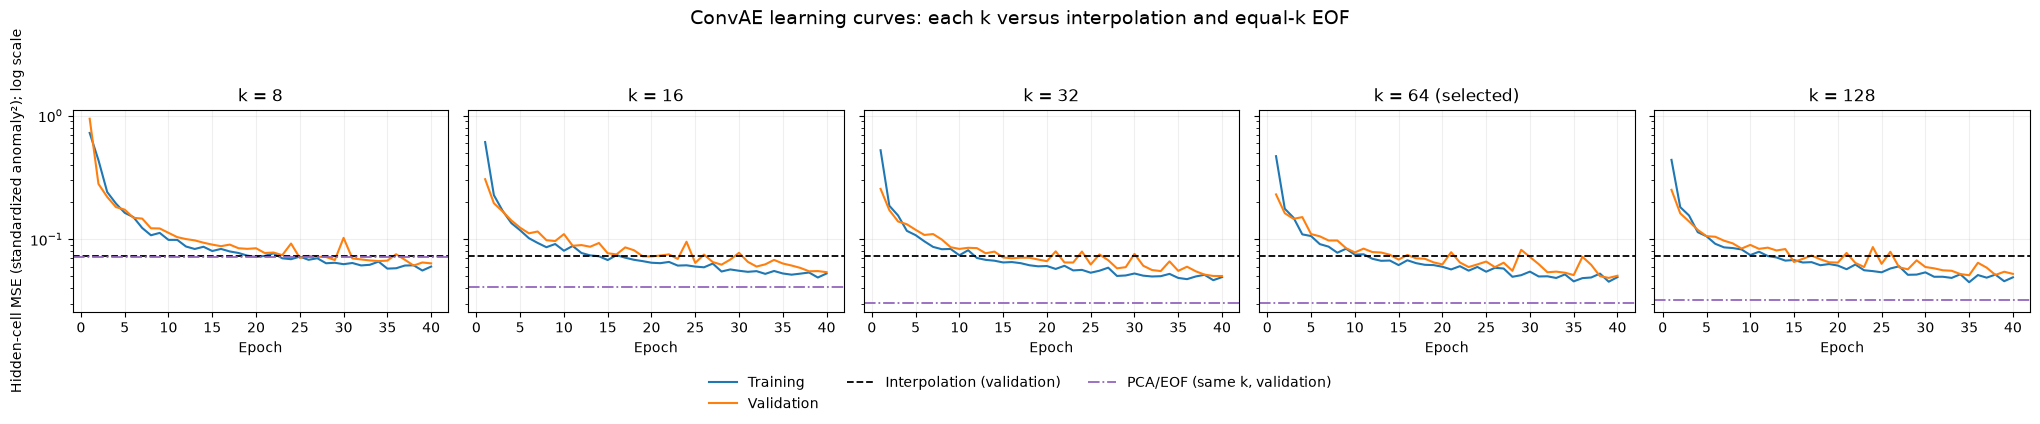

The horizontal references use the exact validation targets/masks used for every ConvAE validation curve.
Training uses changing masks; compare the reference lines primarily with the validation curves.


In [128]:
# Code step 27
USE_LOG_LOSS_AXIS = True  # Similar to the supplied example; all panels share the same y scale.
SHOW_CLIMATOLOGY_REFERENCE = False
fig, axes = plt.subplots(
    1,
    len(CONV_LATENT_DIMS),
    figsize=(4.1 * len(CONV_LATENT_DIMS), 4.2),
    sharex=True,
    sharey=True,
    squeeze=False,
)
all_losses = [interpolation_validation_mse] + list(eof_mse_by_k.values())
if SHOW_CLIMATOLOGY_REFERENCE:
    all_losses.append(climatology_validation_mse)
for latent_dim in CONV_LATENT_DIMS:
    history = pd.DataFrame(histories[run_name("ConvAE", latent_dim)])
    all_losses.extend(history.train_mse.tolist())
    all_losses.extend(history.validation_mse.tolist())
use_log_scale = USE_LOG_LOSS_AXIS and min(all_losses) > 0
if USE_LOG_LOSS_AXIS and not use_log_scale:
    warnings.warn(
        "At least one loss is zero/nonpositive: use a linear loss axis instead of dropping valid points."
    )
for axis, latent_dim in zip(axes.flat, CONV_LATENT_DIMS):
    history = pd.DataFrame(histories[run_name("ConvAE", latent_dim)])
    axis.plot(history.epoch, history.train_mse, color="tab:blue", label="Training")
    axis.plot(history.epoch, history.validation_mse, color="tab:orange", label="Validation")
    axis.axhline(
        interpolation_validation_mse,
        color="black",
        linestyle="--",
        linewidth=1.3,
        label="Interpolation (validation)",
    )
    if SHOW_CLIMATOLOGY_REFERENCE:
        axis.axhline(
            climatology_validation_mse,
            color="gray",
            linestyle=":",
            linewidth=1.3,
            label="Seasonal reference (validation)",
        )
    if latent_dim in eof_mse_by_k:
        axis.axhline(
            eof_mse_by_k[latent_dim],
            color="tab:purple",
            linestyle="-.",
            linewidth=1.3,
            label="PCA/EOF (same k, validation)",
        )
    title = f"k = {latent_dim}"
    if latent_dim == selected_conv_k:
        title += " (selected)"
    axis.set(title=title, xlabel="Epoch")
    if use_log_scale:
        axis.set_yscale("log")
    axis.grid(alpha=0.2)
axes[0, 0].set_ylabel(
    "Hidden-cell MSE (standardized anomaly²)" + ("; log scale" if use_log_scale else "")
)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=3 if not SHOW_CLIMATOLOGY_REFERENCE else 5,
    frameon=False,
)
fig.suptitle("ConvAE learning curves: each k versus interpolation and equal-k EOF", fontsize=14)
fig.tight_layout(rect=[0, 0.12, 1, 0.91])
fig.savefig(OUTPUT_DIR / "convae_all_k_side_by_side.png", dpi=180, bbox_inches="tight")
plt.show()
print(
    "The horizontal references use the exact validation targets/masks used for every ConvAE validation curve."
)
print(
    "Training uses changing masks; compare the reference lines primarily with the validation curves."
)


**Figure interpretation:** Compare orange validation loss with black interpolation and purple equal-k EOF on exactly the same hidden pixels and MSE scale. Lower means better validation gap filling. EOF lines may differ between panels because k changes. Training loss uses changing masks, so baseline comparisons primarily concern validation. Same k does not equalize parameter count or compute.

**Code step 28**

## 15f. Compare validation learning curves for all k

**Purpose:** How does latent width affect learning and validation error?

**Input:** All five ConvAE histories and the validation-selected k.

**Operation:** Overlay validation MSE versus epoch, emphasizing the selected k.

**Output:** Combined validation-curve figure.

**Lecture connection:** Capacity affects gap filling; larger k is not guaranteed to improve unseen reconstruction.

**Expected shapes:** One variable-length epoch series per k.

**Data leakage check:** Validation comparison only. All models share mask banks and training RNG sequences.

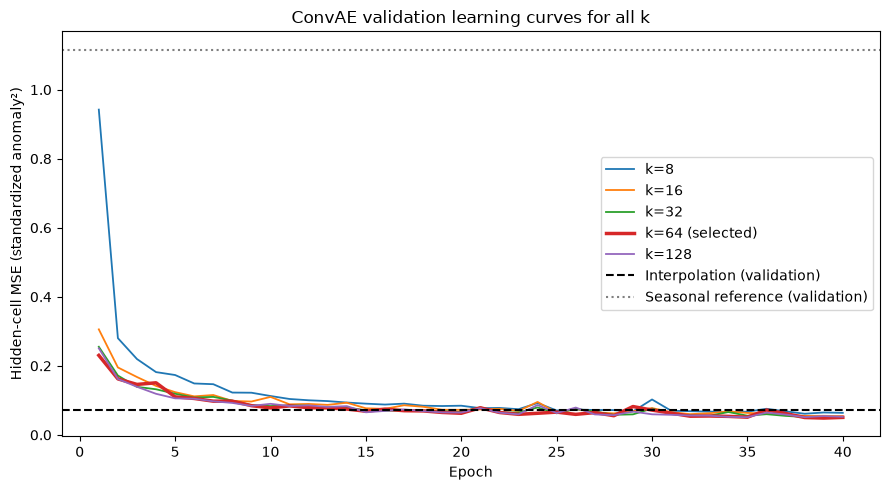

In [129]:
# Code step 28
fig, axis = plt.subplots(figsize=(9, 5))
for latent_dim in CONV_LATENT_DIMS:
    history = pd.DataFrame(histories[run_name("ConvAE", latent_dim)])
    label = f"k={latent_dim}"
    if latent_dim == selected_conv_k:
        label += " (selected)"
    axis.plot(
        history.epoch,
        history.validation_mse,
        label=label,
        linewidth=2.5 if latent_dim == selected_conv_k else 1.3,
    )
axis.set(
    title="ConvAE validation learning curves for all k",
    xlabel="Epoch",
    ylabel="Hidden-cell MSE (standardized anomaly²)",
)
axis.axhline(
    interpolation_validation_mse,
    color="black",
    linestyle="--",
    label="Interpolation (validation)",
)
axis.axhline(
    climatology_validation_mse,
    color="gray",
    linestyle=":",
    label="Seasonal reference (validation)",
)
axis.legend()
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "convae_all_k_validation_curves.png", dpi=160, bbox_inches="tight")
plt.show()


**Figure interpretation:** The selected model minimizes its best recorded validation MSE, not its final-epoch loss or its test error. Different stopping epochs are expected.

**Code step 29**

## 15g. Best validation gap-filling error versus k

**Purpose:** Which latent width gives the best validation reconstruction?

**Input:** Best validation checkpoints for every ConvAE k.

**Operation:** Report the validation table and plot physical-unit RMSE versus latent width.

**Output:** Validation-only k table and RMSE plot in °C.

**Lecture connection:** Choose architecture capacity based on held-out gap filling, not training loss.

**Expected shapes:** Five candidate rows; one selected k.

**Data leakage check:** No test results enter this plot or selection.

,latent_dim,best_epoch,epochs_run,best_validation_RMSE_C,parameters,RMSE_gain_vs_interpolation_percent
0,8,38,40,0.383855,147353,8.383302
1,16,40,40,0.361006,276897,13.836666
2,32,40,40,0.348297,535985,16.870020
3,64,39,40,0.342238,1054161,18.316233
4,128,35,40,0.350821,2090513,16.267641


,latent_dim,best_validation_RMSE_C,EOF_validation_RMSE_C,ConvAE_minus_EOF_RMSE_C
0,8,0.383855,0.415747,-0.031892
1,16,0.361006,0.315710,0.045297
2,32,0.348297,0.271338,0.076960
3,64,0.342238,0.271845,0.070393
4,128,0.350821,0.277473,0.073348


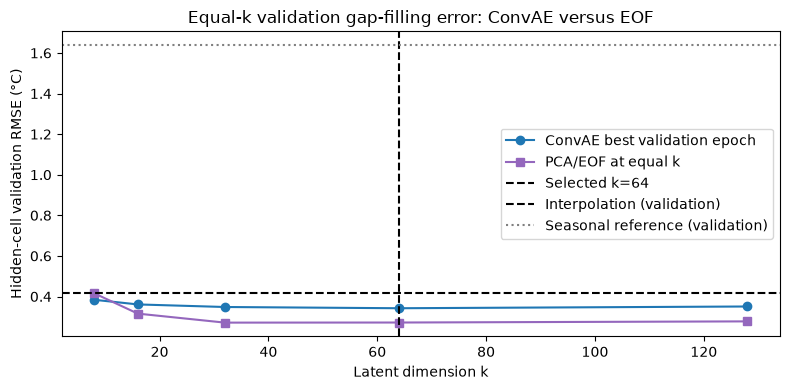

In [130]:
# Code step 29
comparison = conv_validation_table.sort_values("latent_dim")
interpolation_validation_rmse = interpolation_validation_mse**0.5 * training_anomaly_std
comparison = comparison.copy()
comparison["RMSE_gain_vs_interpolation_percent"] = (
    100
    * (interpolation_validation_rmse - comparison.best_validation_RMSE_C)
    / interpolation_validation_rmse
    if interpolation_validation_rmse > 0
    else np.nan
)
display(
    comparison[
        [
            "latent_dim",
            "best_epoch",
            "epochs_run",
            "best_validation_RMSE_C",
            "parameters",
            "RMSE_gain_vs_interpolation_percent",
        ]
    ]
)
comparison = comparison.merge(
    eof_validation_by_k[["k", "RMSE_C"]].rename(
        columns={"k": "latent_dim", "RMSE_C": "EOF_validation_RMSE_C"}
    ),
    on="latent_dim",
    how="left",
)
comparison["ConvAE_minus_EOF_RMSE_C"] = (
    comparison.best_validation_RMSE_C - comparison.EOF_validation_RMSE_C
)
display(
    comparison[
        [
            "latent_dim",
            "best_validation_RMSE_C",
            "EOF_validation_RMSE_C",
            "ConvAE_minus_EOF_RMSE_C",
        ]
    ]
)
comparison.to_csv(OUTPUT_DIR / "convae_k_validation_comparison.csv", index=False)
fig, axis = plt.subplots(figsize=(8, 4))
axis.plot(
    comparison.latent_dim,
    comparison.best_validation_RMSE_C,
    "o-",
    label="ConvAE best validation epoch",
)
axis.plot(
    eof_validation_by_k.k,
    eof_validation_by_k.RMSE_C,
    "s-",
    color="tab:purple",
    label="PCA/EOF at equal k",
)
axis.axvline(
    selected_conv_k, linestyle="--", color="black", label=f"Selected k={selected_conv_k}"
)
axis.set(
    title="Equal-k validation gap-filling error: ConvAE versus EOF",
    xlabel="Latent dimension k",
    ylabel="Hidden-cell validation RMSE (°C)",
)
axis.axhline(
    interpolation_validation_rmse,
    color="black",
    linestyle="--",
    label="Interpolation (validation)",
)
axis.axhline(
    climatology_validation_mse**0.5 * training_anomaly_std,
    color="gray",
    linestyle=":",
    label="Seasonal reference (validation)",
)
axis.legend()
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "convae_k_validation_rmse.png", dpi=150, bbox_inches="tight")
plt.show()


**Code step 30**

## Latent size and compression ratio

**Purpose:** How much representation capacity does each k retain?

**Input:** Grid cell count, all-k validation tables and model parameter counts.

**Operation:** Calculate D/k for the physical field and plot validation error against that ratio.

**Output:** CSV capacity table and a compression-versus-validation-error graph.

**Lecture connection:** Bottleneck dimension k versus original field dimension D.

**Expected shapes:** D=H×W for one temperature field; each ConvAE latent code [B,k].

**Data leakage check:** Only validation scores appear; this is not a test-based trade-off selection.


,k,D,D_over_k,ConvAE_validation_RMSE_C,EOF_validation_RMSE_C,ConvAE_parameters
0,8,3649,456.125000,0.383855,0.415747,147353
1,16,3649,228.062500,0.361006,0.315710,276897
2,32,3649,114.031250,0.348297,0.271338,535985
3,64,3649,57.015625,0.342238,0.271845,1054161
4,128,3649,28.507812,0.350821,0.277473,2090513


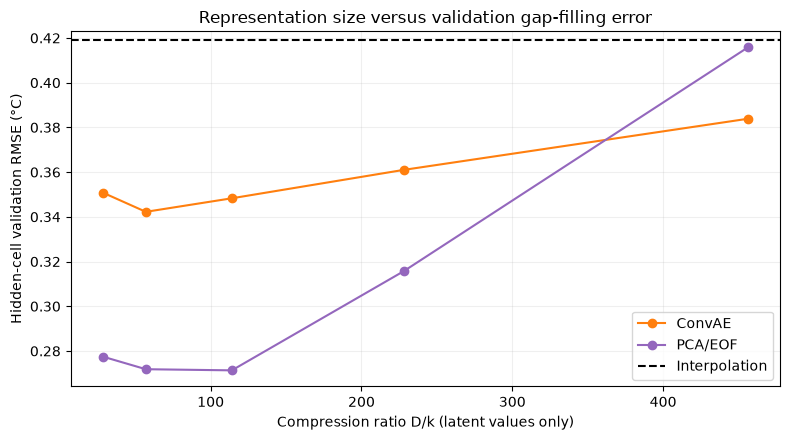

D/k excludes model weights, the mask channel and saved preprocessing. Equal k does not mean equal parameter count.


In [131]:
# Code step 30
capacity_table = comparison[["latent_dim", "best_validation_RMSE_C", "EOF_validation_RMSE_C", "parameters"]].copy()
capacity_table = capacity_table.rename(columns={"latent_dim": "k", "best_validation_RMSE_C": "ConvAE_validation_RMSE_C", "parameters": "ConvAE_parameters"})
capacity_table.insert(1, "D", grid_cell_count)
capacity_table.insert(2, "D_over_k", grid_cell_count / capacity_table.k)
display(capacity_table)
capacity_table.to_csv(OUTPUT_DIR / "latent_capacity_validation.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
for column, label, color in [("ConvAE_validation_RMSE_C", "ConvAE", "tab:orange"), ("EOF_validation_RMSE_C", "PCA/EOF", "tab:purple")]:
    ax.plot(capacity_table.D_over_k, capacity_table[column], "o-", label=label, color=color)
ax.axhline(interpolation_validation_rmse, color="black", linestyle="--", label="Interpolation")
ax.set(title="Representation size versus validation gap-filling error", xlabel="Compression ratio D/k (latent values only)", ylabel="Hidden-cell validation RMSE (°C)")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "compression_vs_validation_rmse.png", dpi=160)
plt.show()
print("D/k excludes model weights, the mask channel and saved preprocessing. Equal k does not mean equal parameter count.")

**Figure interpretation:** A larger D/k means fewer latent values and stronger compression. This is a capacity diagnostic for gap filling, not a file-storage benchmark. The Transformer embedding width is not the same quantity as ConvAE k.


**Figure interpretation:** k changes both representation capacity and parameter count. A single seed and finite training budget limit conclusions about the optimal value.

**Code step 31**

# 16. Experiment C — define the Spatial Transformer

**Purpose:** Can attention between spatial patches help fill a daily temperature map?

**Input:** Two channels: masked standardized anomaly and hidden indicator; original patch-encoder architecture.

**Operation:** Pad bottom/right; project non-overlapping patches, add learned spatial positions, apply self-attention and fold predicted patches back.

**Output:** ERA5Transformer class, separate from ConvAE.

**Lecture connection:** Attention connects positions inside one field; no time-series context.

**Expected shapes:** [B,2,Hp,Wp] → [B,N_patches,2×patch_area] → [B,N_patches,d] → [B,H,W].

**Data leakage check:** Model settings declared before testing; mask hidden values inside the forward method.

In [132]:
# Code step 31
class ERA5Transformer(nn.Module):

    def __init__(self, map_height, map_width, patch_size=4, d=64, nhead=4, nlayers=2, d_ff=128):
        super().__init__()
        self.map_height = map_height
        self.map_width = map_width
        self.patch_size = patch_size
        self.padded_height = math.ceil(map_height / patch_size) * patch_size
        self.padded_width = math.ceil(map_width / patch_size) * patch_size
        self.patch_rows = self.padded_height // patch_size
        self.patch_cols = self.padded_width // patch_size
        self.n_tokens = self.patch_rows * self.patch_cols
        self.patch_area = patch_size * patch_size
        self.inp = nn.Linear(2 * self.patch_area, d)
        self.pos = nn.Embedding(self.n_tokens, d)
        layer = nn.TransformerEncoderLayer(
            d_model=d, nhead=nhead, dim_feedforward=d_ff, dropout=0.1, batch_first=True
        )
        self.enc = nn.TransformerEncoder(layer, num_layers=nlayers)
        self.head = nn.Linear(d, self.patch_area)

    def forward(self, masked_maps, masks, trace=False):
        if (
            masked_maps.ndim != 3
            or masked_maps.shape != masks.shape
            or masked_maps.shape[-2:] != (self.map_height, self.map_width)
        ):
            raise ValueError("Expected matching maps/masks [B,H,W]")
        values = masked_maps.masked_fill(masks, 0).unsqueeze(1)
        missing = masks.unsqueeze(1).to(dtype=values.dtype)
        pad_h = self.padded_height - self.map_height
        pad_w = self.padded_width - self.map_width
        values = F.pad(values, (0, pad_w, 0, pad_h))
        missing = F.pad(missing, (0, pad_w, 0, pad_h), value=1.0)
        # A token represents a spatial patch, not a time step.
        patches = F.unfold(
            torch.cat((values, missing), dim=1),
            kernel_size=self.patch_size,
            stride=self.patch_size,
        ).transpose(1, 2)
        positions = torch.arange(self.n_tokens, device=masked_maps.device)
        tokens = self.inp(patches) + self.pos(positions).unsqueeze(0)
        # Self-attention relates patches inside each map, never different batch examples.
        encoded = self.enc(tokens)
        patch_values = self.head(encoded).transpose(1, 2)
        reconstruction = F.fold(
            patch_values,
            output_size=(self.padded_height, self.padded_width),
            kernel_size=self.patch_size,
            stride=self.patch_size,
        )
        output = reconstruction[:, 0, : self.map_height, : self.map_width]
        if trace:
            print(
                {
                    "masked_input": tuple(masked_maps.shape),
                    "padded_values": tuple(values.shape),
                    "patches": tuple(patches.shape),
                    "tokens": tuple(tokens.shape),
                    "encoded_tokens": tuple(encoded.shape),
                    "padded_reconstruction": tuple(reconstruction.shape),
                    "cropped_output": tuple(output.shape),
                }
            )
        return output


**Code step 32**

## 17. Experiment C — inspect spatial tokens and output alignment

**Purpose:** What does each attention token represent?

**Input:** Dummy batch and fixed patch settings.

**Operation:** Trace patch/token/reconstruction shapes, parameter count and padding fraction.

**Output:** Transformer shape trace; number of spatial tokens; spatial-attention explanation.

**Lecture connection:** A token is one map patch, not one day. Batch examples do not attend to each other.

**Expected shapes:** For 41×89 with 4×4 patches: padded 44×92 and 253 spatial tokens. Actual shapes printed.

**Data leakage check:** Dummy tensor only; no fit or held-out values.

In [133]:
# Code step 32
set_seed(SEED)
demo = build_model("Spatial Transformer")
with torch.no_grad():
    out = demo(
        torch.zeros(2, map_height, map_width),
        torch.zeros(2, map_height, map_width, dtype=torch.bool),
        trace=True,
    )
assert out.shape == (2, map_height, map_width)
print(
    "Patch size:",
    demo.patch_size,
    "spatial token rows/columns:",
    demo.patch_rows,
    demo.patch_cols,
    "tokens:",
    demo.n_tokens,
)
print("Transformer parameters:", sum((p.numel() for p in demo.parameters())))
print(
    "Attention relates patches WITHIN one daily map. No cross-day attention or temporal forecasting."
)
print(
    "Padded-cell fraction:",
    (demo.padded_height * demo.padded_width - map_height * map_width)
    / (map_height * map_width),
)
del demo


{'masked_input': (2, 41, 89), 'padded_values': (2, 1, 44, 92), 'patches': (2, 253, 32), 'tokens': (2, 253, 64), 'encoded_tokens': (2, 253, 64), 'padded_reconstruction': (2, 1, 44, 92), 'cropped_output': (2, 41, 89)}
Patch size: 4 spatial token rows/columns: 11 23 tokens: 253
Transformer parameters: 86288
Attention relates patches WITHIN one daily map. No cross-day attention or temporal forecasting.
Padded-cell fraction: 0.10934502603453


**Code step 33**

## 18. Experiment C — train Spatial Transformer

**Purpose:** How well does patch attention learn the same hidden-cell task?

**Input:** Spatial Transformer, same training fields, batch order/mask RNG and fixed validation bank.

**Operation:** Train using shared MSE/early-stopping helper with the declared Transformer learning rate.

**Output:** Separate Transformer checkpoint and epoch history.

**Lecture connection:** Spatial self-attention for reconstruction.

**Expected shapes:** Prediction/target [B,H,W].

**Data leakage check:** Training updates only; validation selects checkpoint; no test-based tuning.

In [134]:
# Code step 33
# Separate model, but the same split, masks and hidden-cell objective.
train_model("Spatial Transformer")


Spatial Transformer: epoch 01; training MSE=0.743375; validation MSE=0.488673
Spatial Transformer: epoch 02; training MSE=0.433319; validation MSE=0.407624
Spatial Transformer: epoch 03; training MSE=0.414391; validation MSE=0.390980
Spatial Transformer: epoch 04; training MSE=0.381731; validation MSE=0.357770
Spatial Transformer: epoch 05; training MSE=0.384184; validation MSE=0.363250
Spatial Transformer: epoch 06; training MSE=0.364865; validation MSE=0.343193
Spatial Transformer: epoch 07; training MSE=0.344273; validation MSE=0.336393
Spatial Transformer: epoch 08; training MSE=0.332397; validation MSE=0.324398
Spatial Transformer: epoch 09; training MSE=0.340612; validation MSE=0.317867
Spatial Transformer: epoch 10; training MSE=0.334472; validation MSE=0.307812
Spatial Transformer: epoch 11; training MSE=0.340207; validation MSE=0.302486
Spatial Transformer: epoch 12; training MSE=0.309035; validation MSE=0.314263
Spatial Transformer: epoch 13; training MSE=0.306603; validation

C:\Users\sraje\AppData\Local\Temp\ipykernel_23280\2495030240.py:168: UserWarning: Spatial Transformer: validation improved near the epoch budget; convergence is not established.
  warnings.warn(


Spatial Transformer: checkpoint reload verified (MSE=0.150098)


**Code step 34**

## 19. Experiment C — Transformer learning curve

**Purpose:** Does the Transformer generalize during training?

**Input:** Transformer epoch history.

**Operation:** Plot training and validation hidden-cell loss.

**Output:** Separate Transformer learning curve.

**Lecture connection:** Held-out reconstruction and optimization.

**Expected shapes:** One scalar per epoch per split.

**Data leakage check:** Training/validation only.

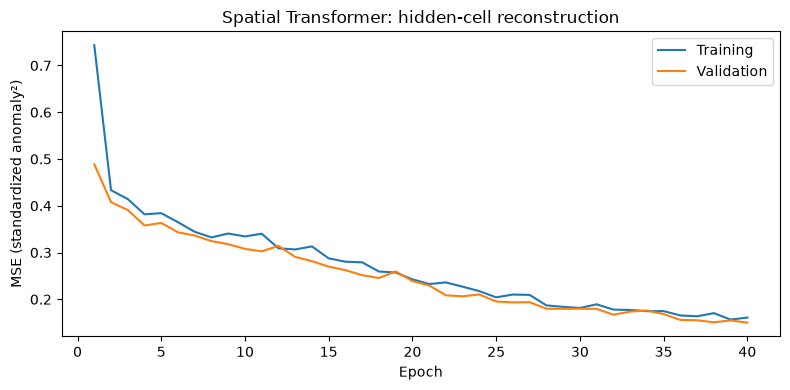

In [135]:
# Code step 34
plot_learning("Spatial Transformer")


**Figure interpretation:** Compare training/validation separation and budget limits. Different model sizes and optimization rates mean these are practical models under a shared protocol, not a controlled proof about attention alone.

**Code step 35**

# 20. Combined neural training summary

**Purpose:** How do optimization progress and model costs compare?

**Input:** Both recorded histories and summaries.

**Operation:** Overlay validation curves and display parameter counts/best epochs.

**Output:** Combined validation plot and training-summary table.

**Lecture connection:** Fair reporting of model complexity and selected epochs.

**Expected shapes:** Two validation series; one summary row per model.

**Data leakage check:** No test inputs or results.

,method,run,latent_dim,best_epoch,epochs_run,best_validation_RMSE_C,parameters,learning_rate
0,ConvAE,ConvAE_k8,8.0,38,40,0.383855,147353,0.0010
1,ConvAE,ConvAE_k16,16.0,40,40,0.361006,276897,0.0010
2,ConvAE,ConvAE_k32,32.0,40,40,0.348297,535985,0.0010
3,ConvAE,ConvAE_k64,64.0,39,40,0.342238,1054161,0.0010
4,ConvAE,ConvAE_k128,128.0,35,40,0.350821,2090513,0.0010
5,Spatial Transformer,Spatial Transformer,NaN,40,40,0.600890,86288,0.0003


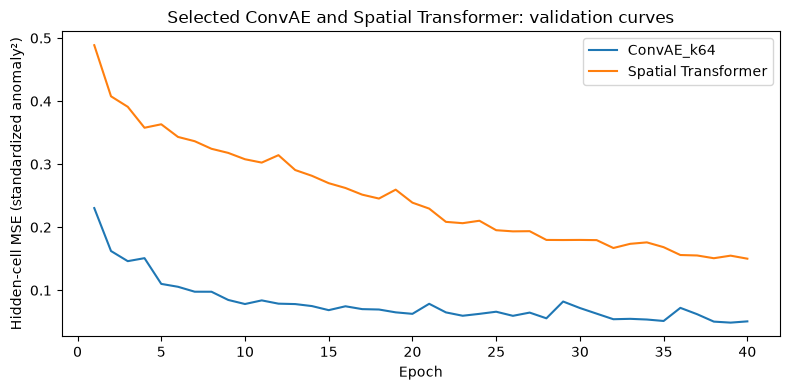

Only the validation-selected ConvAE enters the final four-method test comparison.


In [136]:
# Code step 35
training_summary = pd.DataFrame(training_rows)
display(training_summary)
selected_run = run_name("ConvAE", selected_conv_k)
fig, axis = plt.subplots(figsize=(8, 4))
for label in [selected_run, "Spatial Transformer"]:
    history = pd.DataFrame(histories[label])
    axis.plot(history.epoch, history.validation_mse, label=label)
axis.set(
    title="Selected ConvAE and Spatial Transformer: validation curves",
    xlabel="Epoch",
    ylabel="Hidden-cell MSE (standardized anomaly²)",
)
axis.legend()
plt.tight_layout()
plt.show()
print("Only the validation-selected ConvAE enters the final four-method test comparison.")


**Figure interpretation:** Both checkpoints minimize the same fixed-mask validation objective. This figure reports training behavior, not final test skill.

**Code step 36**

## 21. Final evaluation — all four methods on identical hidden cells

**Purpose:** Which method fills unseen small/large gaps most accurately?

**Input:** Frozen neural checkpoints; fixed validation/test banks; physical targets; training-derived inverse transform.

**Operation:** Use only visible cells as input, inverse to Celsius, pool hidden-cell errors and preserve convergence logs.

**Output:** Per-case metrics, method/gap tables, temperature-anomaly category rows and checks.

**Lecture connection:** Held-out spatial gap reconstruction; no forecasts or complete hidden inputs.

**Expected shapes:** Every prediction [H,W]; each comparison uses the same [N_hidden] cells.

**Data leakage check:** All model choices frozen. Test used for reporting only. Category cutoffs fitted from training anomalies.

In [137]:
# Code step 36
q10, q90 = np.quantile(temperature_anomalies["train"], [0.1, 0.9])
CATEGORY_EDGES = np.array([-np.inf, q10, 0.0, q90, np.inf])
CATEGORY_NAMES = ["Cold tail", "Below seasonal mean", "Above seasonal mean", "Warm tail"]
if not np.all(np.diff(CATEGORY_EDGES) > 0):
    raise ValueError("Expected training anomaly q10 < 0 < q90")
print("Training anomaly category edges (°C):", CATEGORY_EDGES)


def predict_field(method, z, mask, split, i, model=None):
    if method == "Interpolation":
        observed = temperature_maps[split][i].copy()
        observed[mask] = np.nan
        return harmonic_inpaint(observed, mask)
    if method == "PCA/EOF":
        observed = z.copy()
        observed[mask] = np.nan
        pred_z = eof_fill(observed, mask, selected_eof_k)
    else:
        pred_z = neural_predict(model, z, mask)
    return (pred_z * training_anomaly_std + seasonal_reference[split][i], {})


case_rows = []
category_rows = []
convergence_rows = []
for split, bank in [("validation", validation_mask_bank), ("test", test_mask_bank)]:
    for method in METHODS:
        model = None if method in {"Interpolation", "PCA/EOF"} else load_model(method)
        for (gap, draw), masks in bank.items():
            for i, m in enumerate(masks):
                pred, info = predict_field(
                    method, standardized_anomalies[split][i], m, split, i, model
                )
                if pred.shape != (map_height, map_width) or not np.isfinite(pred).all():
                    raise ValueError("Prediction shape/finite check failed")
                target = temperature_maps[split][i][m].astype("float64")
                error = pred[m].astype("float64") - target
                common = dict(
                    split=split,
                    method=method,
                    gap=gap,
                    draw=draw,
                    index=i,
                    date=str(split_dates[split][i].date()),
                )
                case_rows.append(
                    dict(
                        **common,
                        n=len(error),
                        se=float(error @ error),
                        ae=float(np.abs(error).sum()),
                        bias_sum=float(error.sum()),
                    )
                )
                if info:
                    convergence_rows.append(dict(**common, **info))
                labels = np.digitize(
                    temperature_anomalies[split][i][m], CATEGORY_EDGES[1:-1], right=True
                )
                for j, label in enumerate(CATEGORY_NAMES):
                    err = error[labels == j]
                    if len(err):
                        category_rows.append(
                            dict(
                                **common,
                                category=label,
                                n=len(err),
                                se=float(err @ err),
                                ae=float(np.abs(err).sum()),
                                bias_sum=float(err.sum()),
                            )
                        )
        if model is not None:
            del model
    if split == "validation":
        # All validation cases are now available; no test targets have been scored yet.
        for method in ["ConvAE", "Spatial Transformer"]:
            label = run_name(method, selected_conv_k if method == "ConvAE" else None)
            saved = load_checkpoint_file(checkpoints[label])
            rows = [r for r in case_rows if r["split"] == "validation" and r["method"] == method]
            actual_mse = sum(r["se"] for r in rows) / sum(r["n"] for r in rows) / training_anomaly_std**2
            expected_mse = float(saved["best_validation_mse"])
            agrees = bool(np.isclose(actual_mse, expected_mse,
                                    rtol=CHECKPOINT_RTOL, atol=CHECKPOINT_ATOL))
            validation_integrity_rows.append(dict(
                run=label, check="final_single_map_physical_evaluation", expected_mse=expected_mse,
                measured_mse=actual_mse, passed=agrees))
            pd.DataFrame(validation_integrity_rows).to_csv(
                OUTPUT_DIR / "validation_integrity.csv", index=False)
            if not agrees:
                pd.DataFrame(case_rows).to_csv(OUTPUT_DIR / "validation_cases_before_stop.csv", index=False)
                raise RuntimeError(
                    f"{label}: final validation does not reproduce checkpoint score. "
                    f"Expected MSE={expected_mse:.9g}, measured={actual_mse:.9g}. "
                    "Test scoring blocked. Check validation_integrity.csv and rerun from a fresh kernel. "
                    "This may reflect changed preprocessing/state or a batched/single-map backend issue; "
                    "the cause has not been established. Do not relax this check to obtain a ranking.")
        print("Validation integrity passed for both neural models; test scoring may now start.")

case_metrics = pd.DataFrame(case_rows)
category_case_metrics = pd.DataFrame(category_rows)
convergence = pd.DataFrame(convergence_rows)


def aggregate(frame, keys):
    a = frame.groupby(keys, as_index=False).agg(
        n=("n", "sum"), se=("se", "sum"), ae=("ae", "sum"), bias_sum=("bias_sum", "sum")
    )
    a["RMSE_C"] = np.sqrt(a.se / a.n)
    a["MAE_C"] = a.ae / a.n
    a["bias_C"] = a.bias_sum / a.n
    return a


gap_metrics = aggregate(case_metrics, ["split", "method", "gap"])
overall_metrics = aggregate(case_metrics, ["split", "method"])
# k and d have different meanings; report them in separate columns.
for score_table in [gap_metrics, overall_metrics]:
    score_table["selected_k"] = score_table.method.map(
        {"PCA/EOF": selected_eof_k, "ConvAE": selected_conv_k}
    )
    score_table["embedding_d"] = score_table.method.map(
        {"Spatial Transformer": TRANSFORMER_CONFIG["d"]}
    )
for split, bank in [("validation", validation_mask_bank), ("test", test_mask_bank)]:
    assert np.allclose(
        standardized_anomalies[split] * training_anomaly_std + seasonal_reference[split],
        temperature_maps[split],
        rtol=1e-05,
        atol=0.0001,
    )
    for (gap, draw), m in bank.items():
        a = case_metrics[
            (case_metrics.split == split)
            & (case_metrics.gap == gap)
            & (case_metrics.draw == draw)
        ]
        assert len(a) == len(METHODS) * len(m)
        for _, row in a.iterrows():
            assert row["n"] == int(m[int(row["index"])].sum())
        assert a.groupby("index").n.nunique().eq(1).all()
case_metrics.to_csv(OUTPUT_DIR / "hidden_cell_cases.csv", index=False)
category_case_metrics.to_csv(OUTPUT_DIR / "temperature_category_cases.csv", index=False)
convergence.to_csv(OUTPUT_DIR / "interpolation_convergence.csv", index=False)
gap_metrics.to_csv(OUTPUT_DIR / "metrics_by_gap.csv", index=False)
overall_metrics.to_csv(OUTPUT_DIR / "metrics_overall.csv", index=False)
if not convergence.converged.all():
    warnings.warn(
        f"{int((~convergence.converged).sum())} interpolation cases did not converge; report numerical caveat"
    )
display(gap_metrics)
display(overall_metrics)
print(
    "Passed inverse-transform and identical evaluation-pixel checks. Subzero Celsius temperatures are valid; no clipping."
)

# Early baseline scores and final validation evaluation must describe the same pixels.
validation_interpolation = overall_metrics[
    (overall_metrics.split == "validation") & (overall_metrics.method == "Interpolation")
].iloc[0]
assert np.isclose(
    validation_interpolation.RMSE_C,
    interpolation_validation_mse**0.5 * training_anomaly_std,
    rtol=1e-5,
)
validation_eof = overall_metrics[
    (overall_metrics.split == "validation") & (overall_metrics.method == "PCA/EOF")
].iloc[0]
selected_eof_reference = eof_validation_by_k[eof_validation_by_k.k == selected_eof_k].iloc[0]
assert np.isclose(validation_eof.RMSE_C, selected_eof_reference.RMSE_C, rtol=1e-5)
print(
    "Baseline checks and neural checkpoint validation checks passed. ConvAE k:",
    selected_conv_k,
    "; EOF k:",
    selected_eof_k,
)


Training anomaly category edges (°C): [       -inf -1.9302702   0.          1.83818598         inf]
Validation integrity passed for both neural models; test scoring may now start.


,split,method,gap,n,se,ae,bias_sum,RMSE_C,MAE_C,bias_C,selected_k,embedding_d
0,test,ConvAE,large,618520,81827.982950,158064.968107,84.760222,0.363726,0.255554,0.000137,64.0,NaN
1,test,ConvAE,small,258129,26241.269284,59018.898101,-5202.041145,0.318841,0.228641,-0.020153,64.0,NaN
2,test,Interpolation,large,618520,139198.882497,153854.907160,-1252.480779,0.474396,0.248747,-0.002025,NaN,NaN
3,test,Interpolation,small,258129,35526.821497,47584.838564,-1707.108796,0.370988,0.184345,-0.006613,NaN,NaN
4,test,PCA/EOF,large,618520,55721.207320,125557.255861,-1478.945583,0.300147,0.202996,-0.002391,32.0,NaN
5,test,PCA/EOF,small,258129,13956.423691,42296.986523,1188.980894,0.232524,0.163860,0.004606,32.0,NaN
6,test,Spatial Transformer,large,618520,241577.542080,273278.461447,44314.017760,0.624959,0.441826,0.071645,NaN,64.0
7,test,Spatial Transformer,small,258129,83977.939712,103308.941497,16060.674098,0.570380,0.400222,0.062220,NaN,64.0
8,validation,ConvAE,large,619669,76022.384049,154951.631743,-10022.442032,0.350260,0.250055,-0.016174,64.0,NaN
9,validation,ConvAE,small,254651,26383.940967,58053.731838,-4860.762445,0.321882,0.227974,-0.019088,64.0,NaN


,split,method,n,se,ae,bias_sum,RMSE_C,MAE_C,bias_C,selected_k,embedding_d
0,test,ConvAE,876649,108069.252234,217083.866209,-5117.280923,0.351106,0.247629,-0.005837,64.0,NaN
1,test,Interpolation,876649,174725.703994,201439.745724,-2959.589575,0.446442,0.229784,-0.003376,NaN,NaN
2,test,PCA/EOF,876649,69677.631011,167854.242384,-289.964689,0.281925,0.191473,-0.000331,32.0,NaN
3,test,Spatial Transformer,876649,325555.481792,376587.402944,60374.691858,0.609396,0.429576,0.068870,NaN,64.0
4,validation,ConvAE,874320,102406.325016,213005.363581,-14883.204477,0.342238,0.243624,-0.017023,64.0,NaN
5,validation,Interpolation,874320,153481.263532,194249.179589,-11515.153434,0.418979,0.222172,-0.013170,NaN,NaN
6,validation,PCA/EOF,874320,64371.027597,161971.084263,-2755.989905,0.271338,0.185254,-0.003152,32.0,NaN
7,validation,Spatial Transformer,874320,315689.538452,374796.582378,61473.458807,0.600890,0.428672,0.070310,NaN,64.0


Passed inverse-transform and identical evaluation-pixel checks. Subzero Celsius temperatures are valid; no clipping.
Baseline checks and neural checkpoint validation checks passed. ConvAE k: 64 ; EOF k: 32


**Code step 37**

## Separate test experiments: RMSE versus interpolation

**Purpose:** Does each validation-selected reconstruction method improve RMSE over the same local baseline?

**Input:** `gap_metrics` after all validation-integrity checks, selected EOF/ConvAE k.

**Operation:** Draw two adjacent panels: EOF versus interpolation, and ConvAE versus interpolation. Share y limits, colours and gap categories.

**Output:** Two-panel test RMSE chart and per-method gains table.

**Lecture connection:** Practical evaluation of independently selected model configurations.

**Expected shapes:** Two panels × two gap sizes × two methods.

**Data leakage check:** Both k values and checkpoints were frozen on validation. Test is scored only after integrity checks.


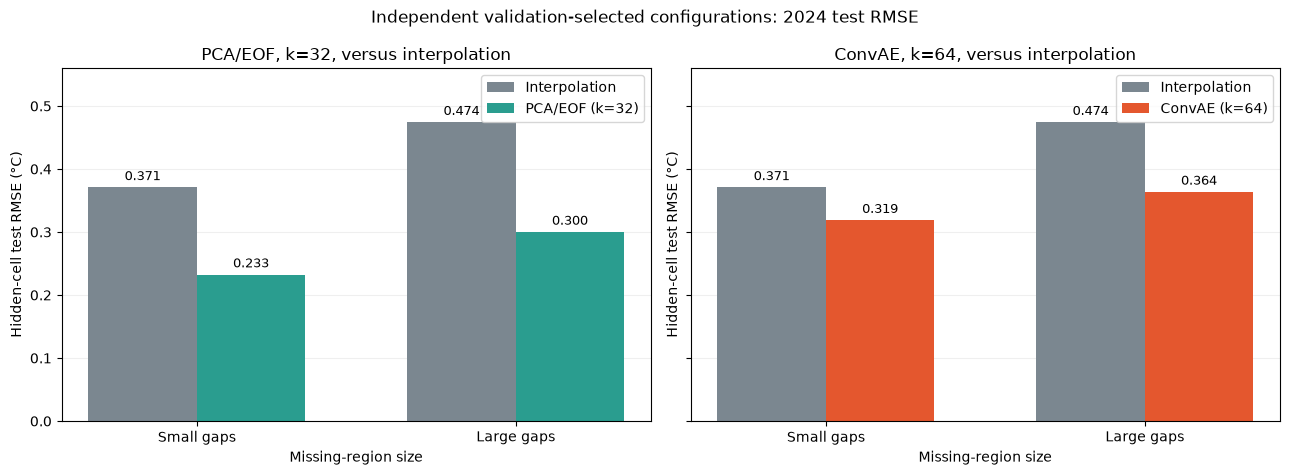

,method,selected_k,gap,metric,baseline,model,gain_percent
0,PCA/EOF,32,small,RMSE_C,0.370988,0.232524,37.322900
1,PCA/EOF,32,large,RMSE_C,0.474396,0.300147,36.730794
2,ConvAE,64,small,RMSE_C,0.370988,0.318841,14.056261
3,ConvAE,64,large,RMSE_C,0.474396,0.363726,23.328661


In [138]:
# Code step 37
METHOD_COLORS = {"Interpolation": "#7B8790", "PCA/EOF": "#2A9D8F", "ConvAE": "#E4572E", "Spatial Transformer": "#4977A5"}
GAP_ORDER = ["small", "large"]

def plot_separate_test_panels(metric, metric_name):
    pairs = [("PCA/EOF", selected_eof_k), ("ConvAE", selected_conv_k)]
    frame = gap_metrics[gap_metrics.split == "test"]
    common_max = float(frame[frame.method.isin(["Interpolation", "PCA/EOF", "ConvAE"])][metric].max()) * 1.18
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True, sharey=True)
    positions = np.arange(len(GAP_ORDER))
    width = 0.34
    gain_rows = []
    for ax, (method, k) in zip(axes, pairs):
        baseline = frame[frame.method == "Interpolation"].set_index("gap").loc[GAP_ORDER, metric].to_numpy()
        learned = frame[frame.method == method].set_index("gap").loc[GAP_ORDER, metric].to_numpy()
        for offset, values, label, color in [(-width/2, baseline, "Interpolation", METHOD_COLORS["Interpolation"]), (width/2, learned, f"{method} (k={k})", METHOD_COLORS[method])]:
            bars = ax.bar(positions + offset, values, width, label=label, color=color)
            ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
        for gap, base, value in zip(GAP_ORDER, baseline, learned):
            gain_rows.append(dict(method=method, selected_k=k, gap=gap, metric=metric, baseline=float(base), model=float(value), gain_percent=100*(base-value)/base if base else np.nan))
        ax.set(title=f"{method}, k={k}, versus interpolation", xlabel="Missing-region size", ylabel=f"Hidden-cell test {metric_name} (°C)", ylim=(0, common_max), xticks=positions, xticklabels=["Small gaps", "Large gaps"])
        ax.legend()
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)
    fig.suptitle(f"Independent validation-selected configurations: 2024 test {metric_name}")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"separate_test_{metric_name.lower()}.png", dpi=180, bbox_inches="tight")
    plt.show()
    gains_table = pd.DataFrame(gain_rows)
    display(gains_table)
    gains_table.to_csv(OUTPUT_DIR / f"separate_test_{metric_name.lower()}_gains.csv", index=False)
    return gains_table

separate_rmse_gains = plot_separate_test_panels("RMSE_C", "RMSE")

**Figure interpretation:** Both panels start at zero and share one y scale. The interpolation bars are the exact same baseline in both panels. k may differ because each method was selected independently on validation. Positive gain means lower error, not necessarily statistically established superiority.


**Code step 38**

## Separate test experiments: MAE versus interpolation

**Purpose:** Does the conclusion change when absolute errors receive linear weight?

**Input:** The same frozen models, cases and hidden cells used for the RMSE panels.

**Operation:** Reuse the two-panel function with MAE and its own shared Celsius axis.

**Output:** Two-panel test MAE chart and gains CSV.

**Lecture connection:** Reconstruction loss sensitivity and complementary error measures.

**Expected shapes:** Two panels × two gap sizes × two methods.

**Data leakage check:** No retraining or model selection from MAE test results.


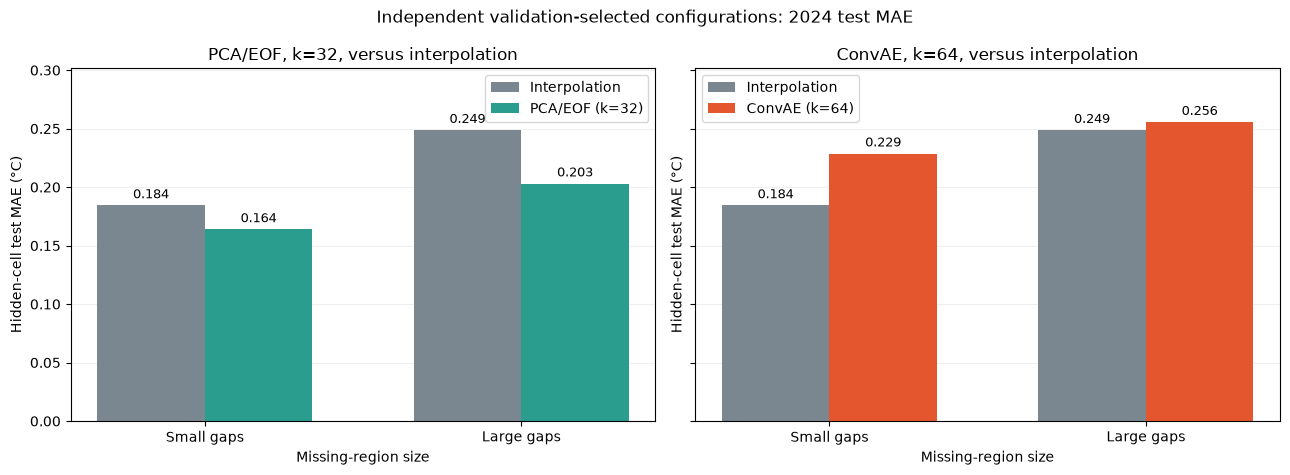

,method,selected_k,gap,metric,baseline,model,gain_percent
0,PCA/EOF,32,small,MAE_C,0.184345,0.163860,11.112472
1,PCA/EOF,32,large,MAE_C,0.248747,0.202996,18.392427
2,ConvAE,64,small,MAE_C,0.184345,0.228641,-24.028787
3,ConvAE,64,large,MAE_C,0.248747,0.255554,-2.736384


In [139]:
# Code step 38
separate_mae_gains = plot_separate_test_panels("MAE_C", "MAE")

**Figure interpretation:** Compare RMSE and MAE together. A method can reduce large squared errors while increasing average absolute error; report both outcomes honestly.


**Code step 39**

## One final table for all four methods

**Purpose:** How do the separately presented experiments relate to the attention experiment?

**Input:** Final pooled and gap-specific test metrics, selected k, Transformer width d.

**Operation:** Display all methods with explicit selected configurations and baseline-relative gains.

**Output:** A complete four-method test summary CSV.

**Lecture connection:** Fair held-out evaluation of local, linear and nonlinear models.

**Expected shapes:** Four rows of pooled metrics, plus gap-specific rows.

**Data leakage check:** No settings are chosen from test rankings.


In [140]:
# Code step 39
final_test_summary = overall_metrics[overall_metrics.split == "test"].copy()
final_test_summary["configuration"] = final_test_summary.method.map({"Interpolation": "No latent k", "PCA/EOF": f"k={selected_eof_k}", "ConvAE": f"k={selected_conv_k}", "Spatial Transformer": f"patch={TRANSFORMER_CONFIG['patch_size']}, d={TRANSFORMER_CONFIG['d']} (not AE k)"})
final_test_summary = final_test_summary.set_index("method").reindex(METHODS).reset_index()
base_rmse = float(final_test_summary.loc[final_test_summary.method == "Interpolation", "RMSE_C"].iloc[0])
final_test_summary["RMSE_gain_vs_interpolation_percent"] = 100*(base_rmse-final_test_summary.RMSE_C)/base_rmse
columns = ["method", "configuration", "n", "RMSE_C", "MAE_C", "bias_C", "RMSE_gain_vs_interpolation_percent"]
display(final_test_summary[columns])
final_test_summary[columns].to_csv(OUTPUT_DIR / "final_four_method_summary.csv", index=False)
print("All scores use the same test masks. Neural validation integrity passed before test evaluation.")

,method,configuration,n,RMSE_C,MAE_C,bias_C,RMSE_gain_vs_interpolation_percent
0,Interpolation,No latent k,876649,0.446442,0.229784,-0.003376,0.000000
1,PCA/EOF,k=32,876649,0.281925,0.191473,-0.000331,36.850737
2,ConvAE,k=64,876649,0.351106,0.247629,-0.005837,21.354718
3,Spatial Transformer,"patch=4, d=64 (not AE k)",876649,0.609396,0.429576,0.068870,-36.500457


All scores use the same test masks. Neural validation integrity passed before test evaluation.


**Code step 40**

## 22. Compare hidden-cell RMSE by gap size

**Purpose:** Which of the four methods has the smallest squared-error-sensitive test metric?

**Input:** Frozen test metrics by method/gap.

**Operation:** Plot pooled pixel RMSE for all four methods.

**Output:** Four-method small/large gap RMSE bar chart in °C.

**Lecture connection:** Held-out reconstruction quality.

**Expected shapes:** Two gap groups × four methods.

**Data leakage check:** Test reporting only.

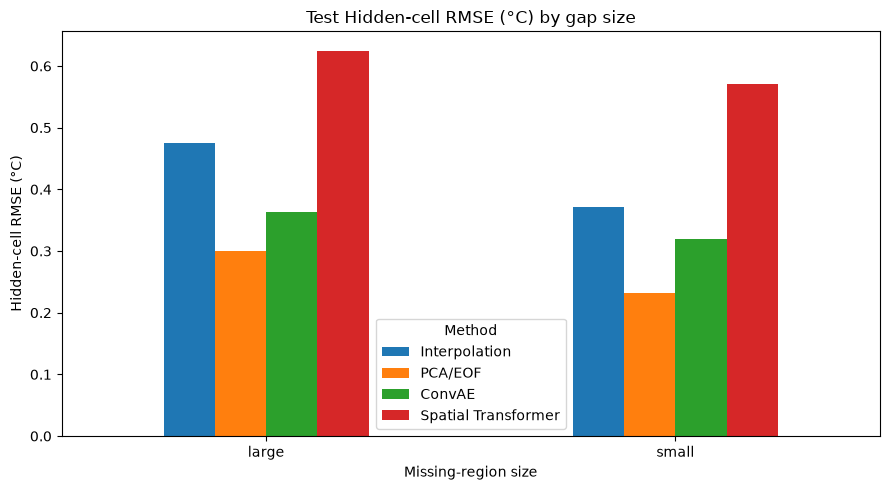

In [141]:
# Code step 40
def plot_gap_metric(metric, label):
    a = (
        gap_metrics[gap_metrics.split == "test"]
        .pivot(index="gap", columns="method", values=metric)
        .reindex(columns=METHODS)
    )
    ax = a.plot.bar(rot=0, figsize=(9, 5))
    ax.set(title="Test " + label + " by gap size", xlabel="Missing-region size", ylabel=label)
    ax.legend(title="Method")
    plt.tight_layout()
    plt.show()


plot_gap_metric("RMSE_C", "Hidden-cell RMSE (°C)")


**Figure interpretation:** All methods reconstruct the same hidden targets. RMSE emphasizes larger errors. Check convergence status and gap-specific behavior before declaring a winner.

**Code step 41**

## 23. Compare hidden-cell MAE by gap size

**Purpose:** Does ranking change under absolute error?

**Input:** The same test comparison table.

**Operation:** Plot pooled pixel MAE.

**Output:** MAE comparison in °C.

**Lecture connection:** Metric choice changes how errors are weighted.

**Expected shapes:** Two gap groups × four methods.

**Data leakage check:** No model selection from test.

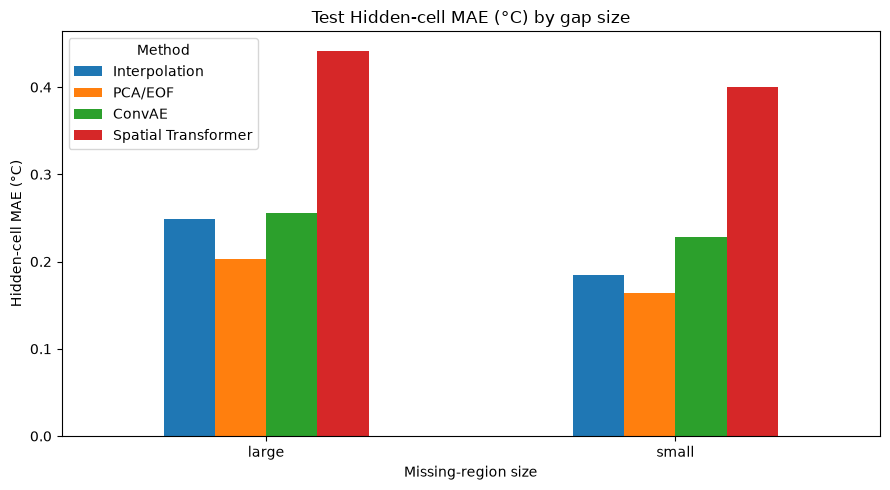

In [142]:
# Code step 41
plot_gap_metric("MAE_C", "Hidden-cell MAE (°C)")


**Figure interpretation:** MAE weights errors linearly. Report it alongside RMSE; a ranking difference is a finding, not a reason to select whichever metric favors a model.

**Code step 42**

## 24. Fixed-day geographic reconstruction and error maps

**Purpose:** What do all four reconstructions look like on the same predeclared test map?

**Input:** TEST_INDEX, DISPLAY_GAP/DRAW, frozen models and the identical hidden mask.

**Operation:** Render physical targets/background/anomalies, mask and all completed maps/errors with geographic context.

**Output:** Twelve-panel fixed_test_reconstruction.png with shared physical and error scales.

**Lecture connection:** Inspect input, reconstructed field and hidden-cell errors.

**Expected shapes:** Each map [H,W]; hidden cells marked independently of temperature values.

**Data leakage check:** Fixed example; no search for the visually best reconstruction.

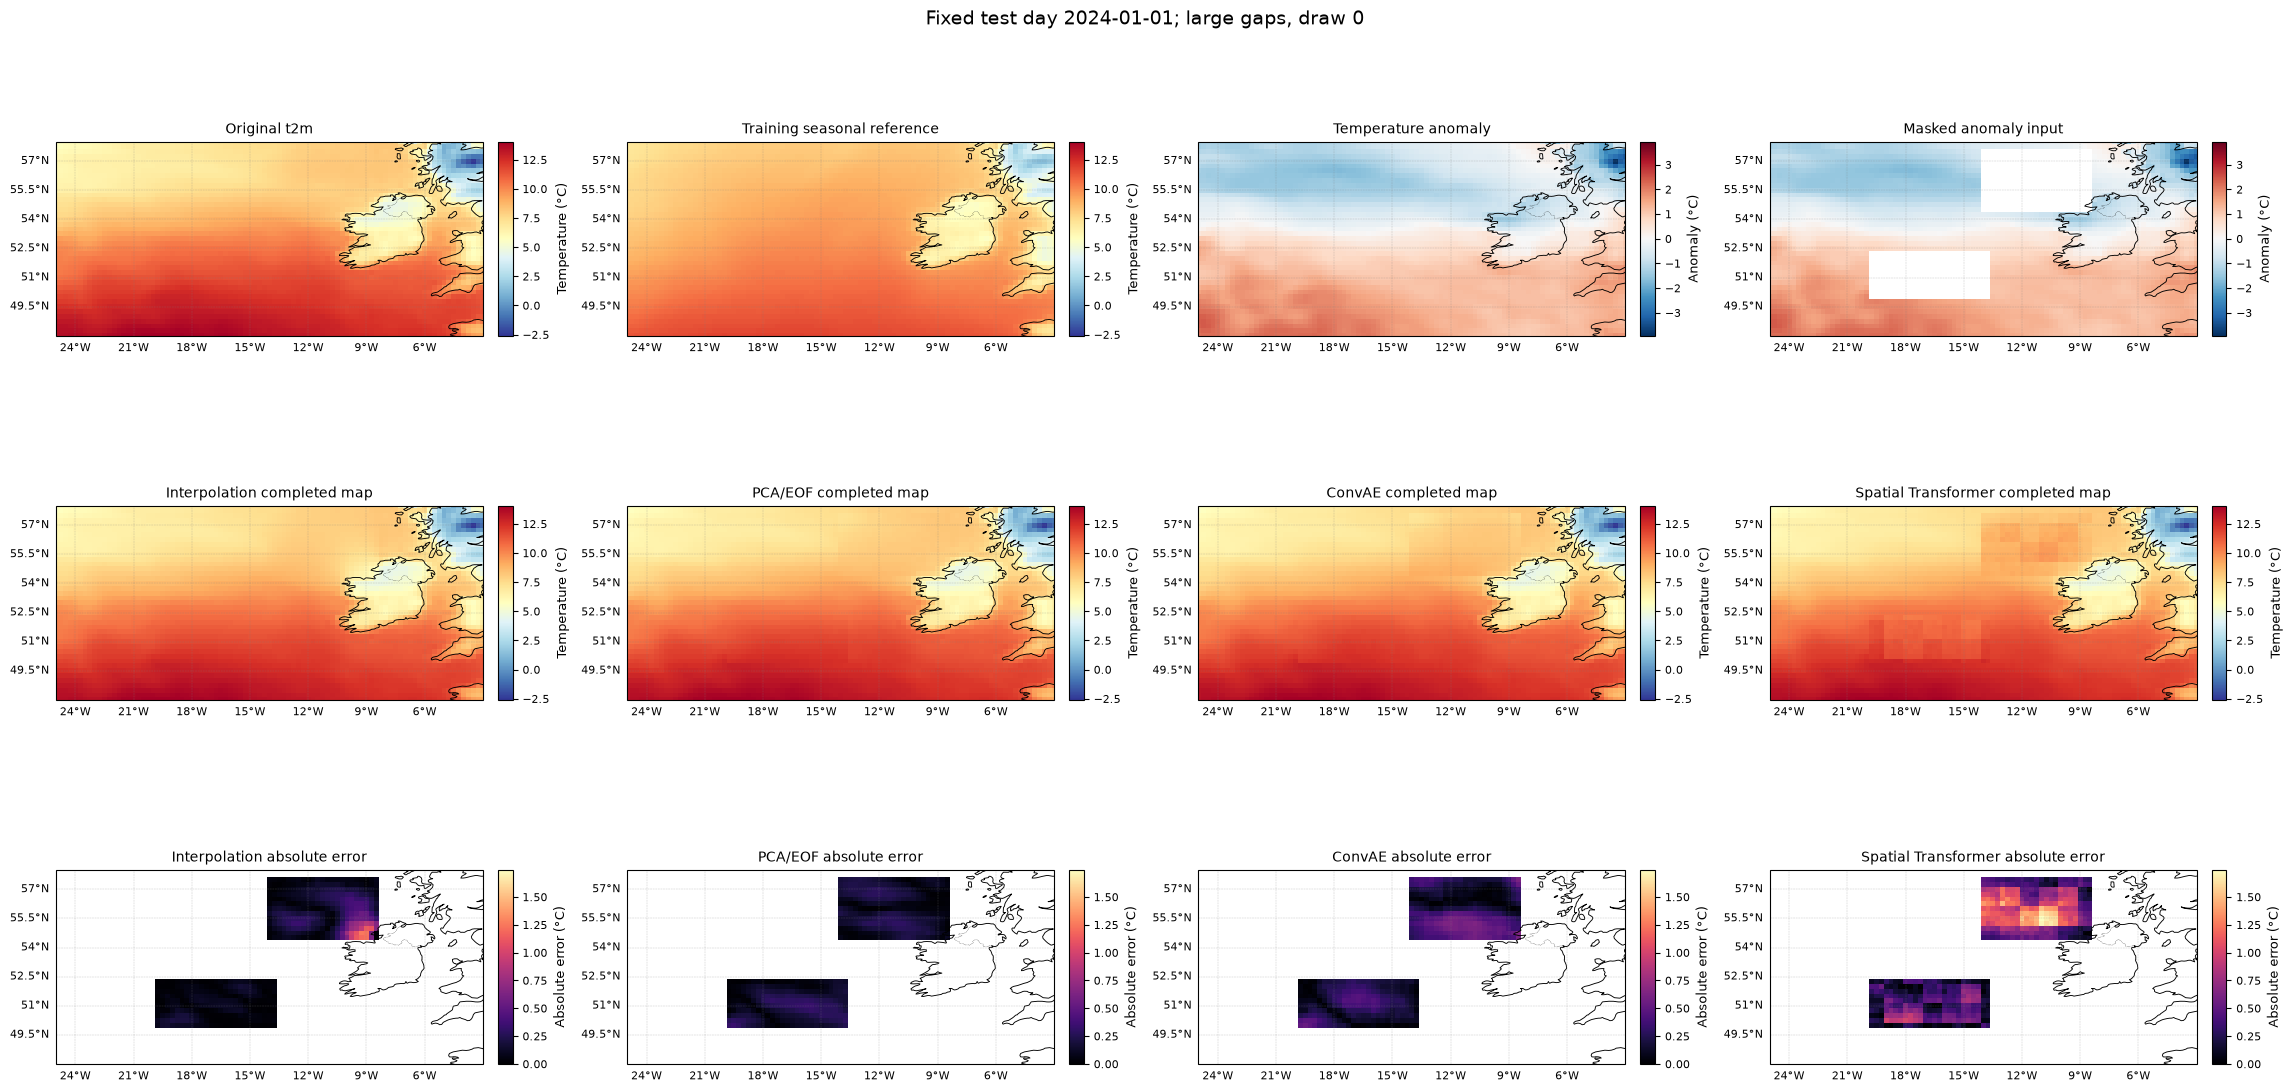

Hidden targets enter scoring only. Interpolation and EOF receive visible values; neural inputs are masked internally too.


In [143]:
# Code step 42
i = TEST_INDEX
if i >= len(standardized_anomalies["test"]):
    raise IndexError("Predeclared test example unavailable")
m = test_mask_bank[DISPLAY_GAP, DISPLAY_DRAW][i]
recon = {}
for method in METHODS:
    model = None if method in {"Interpolation", "PCA/EOF"} else load_model(method)
    pred, _ = predict_field(method, standardized_anomalies["test"][i], m, "test", i, model)
    # Keep observed cells unchanged in the completed maps.
    recon[method] = np.where(m, pred, temperature_maps["test"][i])
    if model is not None:
        del model
orig = temperature_maps["test"][i]
clim = seasonal_reference["test"][i]
anom = temperature_anomalies["test"][i]
lo = min(float(orig.min()), float(clim.min()), min((float(a.min()) for a in recon.values())))
hi = max(float(orig.max()), float(clim.max()), max((float(a.max()) for a in recon.values())))
alim = max(float(np.abs(anom).max()), 1e-06)
errors = {name: np.where(m, np.abs(a - orig), np.nan) for name, a in recon.items()}
emax = max(max((float(np.nanmax(a)) for a in errors.values())), 1e-06)
fig, axes = map_subplots(3, 4, figsize=(23, 12))
panels = [
    (orig, "Original t2m", "Temperature (°C)", lo, hi, TEMPERATURE_CMAP),
    (clim, "Training seasonal reference", "Temperature (°C)", lo, hi, TEMPERATURE_CMAP),
    (anom, "Temperature anomaly", "Anomaly (°C)", -alim, alim, ANOMALY_CMAP),
    (
        np.where(m, np.nan, anom),
        "Masked anomaly input",
        "Anomaly (°C)",
        -alim,
        alim,
        ANOMALY_CMAP,
    ),
]
panels += [
    (recon[name], name + " completed map", "Temperature (°C)", lo, hi, TEMPERATURE_CMAP)
    for name in METHODS
]
panels += [
    (errors[name], name + " absolute error", "Absolute error (°C)", 0, emax, ERROR_CMAP)
    for name in METHODS
]
assert len(panels) == len(axes.flat) == 12
for ax, (a, title, label, vmin, vmax, cmap) in zip(axes.flat, panels):
    map_plot(ax, a, title, label, vmin, vmax, cmap)
fig.suptitle(
    f"Fixed test day {split_dates['test'][i].date()}; {DISPLAY_GAP} gaps, draw {DISPLAY_DRAW}",
    fontsize=14,
)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "fixed_test_reconstruction.png", dpi=160, bbox_inches="tight")
plt.show()
print(
    "Hidden targets enter scoring only. Interpolation and EOF receive visible values; neural inputs are masked internally too."
)


**Figure interpretation:** Completed maps preserve visible values; hidden cells alone contribute to the error maps and metrics. All physical temperature panels share one scale, all error panels share a second, and anomaly panels share a symmetric zero-centred scale. One visual example cannot establish general skill.

**Code step 43**

## 25. Cold/warm anomaly category analysis

**Purpose:** Does performance vary for unusual temperature conditions?

**Input:** Observed test anomalies classified using training-only q10/q90 and zero.

**Operation:** Aggregate RMSE/MAE/bias and unique day counts for each method/category.

**Output:** Category table and error figure; warnings for sparse categories.

**Lecture connection:** Reconstruction limitations and regression toward seasonal expectation.

**Expected shapes:** Four anomaly categories × four methods; repeated mask draws are counted explicitly.

**Data leakage check:** Thresholds use training only; test labels stratify reporting without tuning.

,method,category,n,se,ae,bias_sum,RMSE_C,MAE_C,bias_C,days
0,ConvAE,Above seasonal mean,358515,28537.950464,74851.487172,-8589.078321,0.282135,0.208782,-0.023957,350
1,ConvAE,Below seasonal mean,317873,32727.617538,72789.644621,14920.873488,0.320871,0.228990,0.046940,326
2,ConvAE,Cold tail,57229,21454.602180,25153.837868,9378.289993,0.612283,0.439530,0.163873,161
3,ConvAE,Warm tail,143032,25349.082053,44288.896548,-20827.366083,0.420983,0.309643,-0.145613,215
4,Interpolation,Above seasonal mean,358515,41475.040981,66989.479569,-15304.892215,0.340126,0.186853,-0.042690,350
5,Interpolation,Below seasonal mean,317873,50396.195895,67369.392202,6454.799990,0.398173,0.211938,0.020306,326
6,Interpolation,Cold tail,57229,61234.368392,34802.147463,15144.918772,1.034402,0.608121,0.264637,161
7,Interpolation,Warm tail,143032,21620.098726,32278.726490,-9254.416122,0.388787,0.225675,-0.064702,215
8,PCA/EOF,Above seasonal mean,358515,23086.501078,63913.462469,-5210.799210,0.253761,0.178273,-0.014534,350
9,PCA/EOF,Below seasonal mean,317873,22909.126793,59135.082045,5343.659434,0.268459,0.186034,0.016811,326


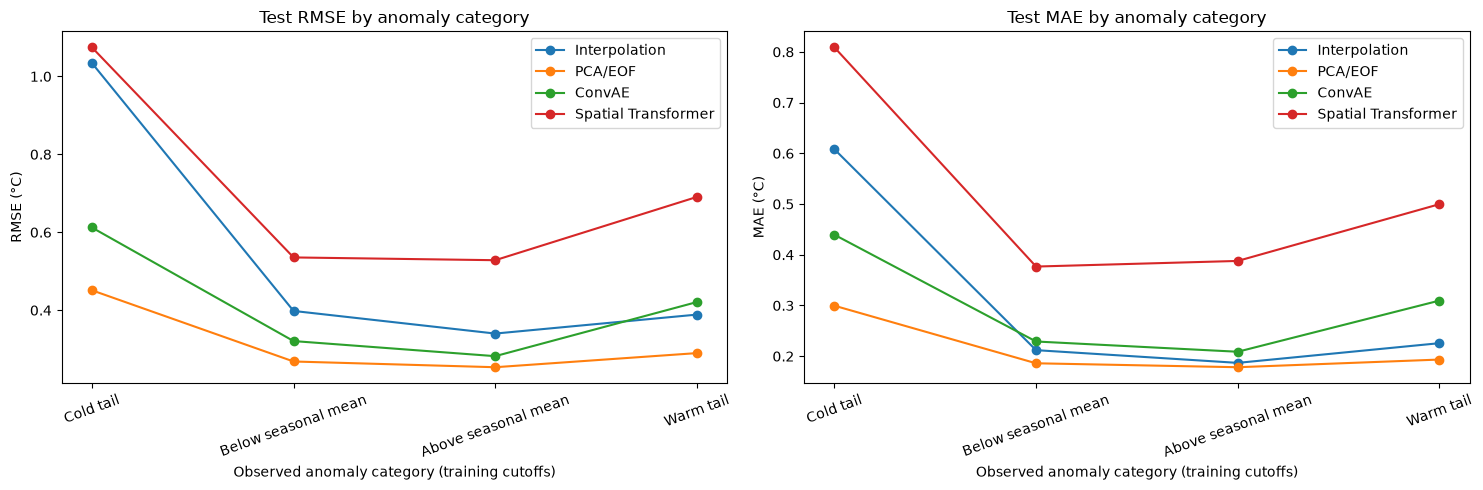

In [144]:
# Code step 43
a = category_case_metrics[category_case_metrics.split == "test"]
category_summary = aggregate(a, ["method", "category"])
category_summary = category_summary.merge(
    a.groupby(["method", "category"], as_index=False).agg(days=("date", "nunique")),
    on=["method", "category"],
)
display(category_summary)
category_summary.to_csv(OUTPUT_DIR / "temperature_anomaly_categories.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metric in zip(axes, ["RMSE_C", "MAE_C"]):
    for method in METHODS:
        b = (
            category_summary[category_summary.method == method]
            .set_index("category")
            .reindex(CATEGORY_NAMES)
        )
        ax.plot(CATEGORY_NAMES, b[metric], "o-", label=method)
    ax.set(
        title="Test " + metric.split("_")[0] + " by anomaly category",
        xlabel="Observed anomaly category (training cutoffs)",
        ylabel=metric.replace("_C", " (°C)"),
    )
    ax.legend()
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()
if (category_summary.days < MIN_CATEGORY_DAYS).any():
    warnings.warn(
        "Some categories have fewer than 20 unique days; avoid strong tail-skill claims"
    )


**Figure interpretation:** Cold-tail positive bias or warm-tail negative bias can indicate smoothing toward typical values. This does not identify the loss function as the sole cause. Pixel/draw counts and unique-day counts are both relevant; neither implies independent weather samples.

**Code step 44**

## 26. Paired uncertainty for learned-method gains over interpolation

**Purpose:** Are measured improvements consistent across held-out days?

**Input:** Identical test cases for each neural method and interpolation; predeclared seven-day block length.

**Operation:** Paired circular moving-block bootstrap of relative hidden-cell RMSE reduction, overall and by gap size.

**Output:** Gain estimates and descriptive 95% intervals, with no forced neural winner.

**Lecture connection:** Measured generalization beyond a point estimate.

**Expected shapes:** Per-day sufficient statistics; bootstrap [1000] relative gains.

**Data leakage check:** No parameter tuning; pairing preserves shared masks and days.

In [145]:
# Code step 44
def paired_gain(frame, method):
    cols = ["date", "draw", "gap", "index"]
    base = frame[frame.method == "Interpolation"]
    other = frame[frame.method == method]
    paired = base[cols + ["n", "se"]].merge(
        other[cols + ["n", "se"]], on=cols, suffixes=("_base", "_model"), validate="one_to_one"
    )
    assert len(paired) == len(base) == len(other) and (paired.n_base == paired.n_model).all()
    daily_table = paired.groupby("date")[["n_base", "se_base", "n_model", "se_model"]].sum().sort_index()
    daily = daily_table.to_numpy(float)

    def gain(t):
        b = np.sqrt(t[1] / t[0])
        v = np.sqrt(t[3] / t[2])
        return (b - v) / b if b > 0 else np.nan

    estimate = gain(daily.sum(axis=0))
    rng = np.random.default_rng(BOOTSTRAP_SEED)
    block = min(BOOTSTRAP_BLOCK_DAYS, len(daily))
    draws = []
    retained_dates = pd.DatetimeIndex(pd.to_datetime(daily_table.index))
    calendar_is_daily = bool(np.all((retained_dates[1:] - retained_dates[:-1]) == pd.Timedelta(days=1)))
    if not calendar_is_daily:
        warnings.warn("Calendar gaps exist: block-bootstrap interval withheld. Point gain only.")
        return dict(method=method, days=len(daily), relative_RMSE_gain=estimate,
                    ci_low=np.nan, ci_high=np.nan,
                    interpretation="No interval: non-consecutive calendar days")
    for _ in range(BOOTSTRAP_DRAWS):
        starts = rng.integers(len(daily), size=math.ceil(len(daily) / block))
        ix = ((starts[:, None] + np.arange(block)) % len(daily)).ravel()[: len(daily)]
        draws.append(gain(daily[ix].sum(axis=0)))
    if not np.isfinite(draws).all():
        raise ValueError("Degenerate baseline/bootstrap RMSE")
    lo, hi = np.quantile(draws, [0.025, 0.975])
    verdict = (
        "Positive gain interval"
        if lo > 0
        else "Negative gain interval" if hi < 0 else "Interval includes zero; uncertain gain"
    )
    if len(daily) < 30:
        verdict = "Too few unique days for a strong inference"
    return dict(
        method=method,
        days=len(daily),
        relative_RMSE_gain=estimate,
        ci_low=lo,
        ci_high=hi,
        interpretation=verdict,
    )


gain_rows = []
for gap in ["all", "small", "large"]:
    frame = case_metrics[case_metrics.split == "test"]
    if gap != "all":
        frame = frame[frame.gap == gap]
    for method in ["PCA/EOF", "ConvAE", "Spatial Transformer"]:
        gain_rows.append(dict(gap=gap, **paired_gain(frame, method)))
gains = pd.DataFrame(gain_rows)
display(gains)
gains.to_csv(OUTPUT_DIR / "paired_gains_vs_interpolation.csv", index=False)
print(
    "Positive gain = lower RMSE than interpolation. One test year, one initialization and the assumed block length limit inference."
)


,gap,method,days,relative_RMSE_gain,ci_low,ci_high,interpretation
0,all,PCA/EOF,366,0.368507,0.300638,0.425116,Positive gain interval
1,all,ConvAE,366,0.213547,0.143924,0.271239,Positive gain interval
2,all,Spatial Transformer,366,-0.365005,-0.483981,-0.254917,Negative gain interval
3,small,PCA/EOF,366,0.373229,0.306046,0.426329,Positive gain interval
4,small,ConvAE,366,0.140563,0.058588,0.208283,Positive gain interval
5,small,Spatial Transformer,366,-0.537462,-0.691042,-0.406951,Negative gain interval
6,large,PCA/EOF,366,0.367308,0.297854,0.426520,Positive gain interval
7,large,ConvAE,366,0.233287,0.161178,0.293020,Positive gain interval
8,large,Spatial Transformer,366,-0.317378,-0.440258,-0.208987,Negative gain interval


Positive gain = lower RMSE than interpolation. One test year, one initialization and the assumed block length limit inference.


**Code step 45**

## 27. Persist the gap-filling protocol and safeguards

**Purpose:** Can this four-method experiment be reproduced?

**Input:** Recorded metadata, masks, preprocessing, settings and results.

**Operation:** Save protocol and confirm model/metric identities, inverse transforms and held-out split separation.

**Output:** protocol.json and explicit assertions.

**Lecture connection:** Reproducible, honest reconstruction evaluation.

**Expected shapes:** Training climatology [365,H,W]; same targets/masks [N,H,W] for all methods.

**Data leakage check:** Training-only climatology/SD; validation-only checkpoints; test reporting only.

In [146]:
# Code step 45
assert climatology.shape == (365, map_height, map_width)
assert set(split_dates["train"].year) <= TRAIN_YEARS
assert set(split_dates["validation"].year) == {VALIDATION_YEAR} and set(
    split_dates["test"].year
) == {TEST_YEAR}
assert set(case_metrics.method) == set(METHODS)
protocol = dict(
    run_id=RUN_ID,
    fingerprint=EXPERIMENT_FINGERPRINT,
    checkpoint_integrity="training reload and pre-test physical validation must agree",
    task="same-day t2m spatial map gap filling",
    methods=METHODS,
    variable=VARIABLE,
    units="degrees Celsius",
    train_years=sorted(TRAIN_YEARS),
    validation_year=VALIDATION_YEAR,
    test_year=TEST_YEAR,
    retained_days={s: len(z) for s, z in standardized_anomalies.items()},
    daily_hours=EXPECTED_HOURS.tolist(),
    climatology_window=CLIMATOLOGY_WINDOW,
    leap_day="Feb29 shares Feb28 slot; later leap dates shifted",
    training_anomaly_std=training_anomaly_std,
    mask_seed=MASK_SEED,
    mask_draws=MASK_DRAWS,
    mask_specs=GAP_SIZES,
    seed=SEED,
    conv_latent_dims=CONV_LATENT_DIMS,
    selected_conv_k=selected_conv_k,
    eof_k_values=EOF_K_VALUES,
    selected_eof_k=selected_eof_k,
    eof_ridge=EOF_RIDGE,
    eof_fit="training maps only; exact full SVD; equal grid-cell weights",
    eof_inference="ridge coefficients from visible pixels only; not DINEOF",
    spatial_transformer=TRANSFORMER_CONFIG,
    attention="spatial patches within one day, not temporal forecasting",
    learning_rates=LEARNING_RATES,
    max_epochs=MAX_EPOCHS,
    patience=PATIENCE,
    interpolation_tolerance_C=INTERPOLATION_TOL,
    interpolation_max_iterations=INTERPOLATION_MAX_ITER,
    bootstrap_draws=BOOTSTRAP_DRAWS,
    bootstrap_block_days=BOOTSTRAP_BLOCK_DAYS,
    bootstrap_seed=BOOTSTRAP_SEED,
    fixed_test_index=TEST_INDEX,
    display_gap=DISPLAY_GAP,
    display_draw=DISPLAY_DRAW,
    selection="ConvAE k and best epochs selected by fixed-mask validation hidden-cell MSE; no test tuning",
    software=dict(
        torch=str(torch.__version__),
        numpy=np.__version__,
        python=platform.python_version(),
        device=str(device),
    ),
)
(OUTPUT_DIR / "protocol.json").write_text(json.dumps(protocol, indent=2, default=str), encoding="utf-8")
print(
    "Saved gap-filling protocol. Review daily exclusions, convergence logs, learning curves and category day counts before conclusions."
)


Saved gap-filling protocol. Review daily exclusions, convergence logs, learning curves and category day counts before conclusions.


**Code step 46**

## 28. Measured five-minute presentation summary

**Purpose:** Which gap-filling conclusions does execution support?

**Input:** Four-method test tables, curves, fixed map and paired gains.

**Operation:** Generate a compact results-driven presentation outline and limitations.

**Output:** summary.md and displayed outline.

**Lecture connection:** Reconstruction accuracy, architecture comparison and validation.

**Expected shapes:** Text populated from measured result tables only.

**Data leakage check:** No predetermined winners or conclusions; results appear after actual execution.

In [147]:
# Code step 46
test = overall_metrics[overall_metrics.split == "test"].set_index("method")
lines = [
    "# Five-minute presentation",
    "1. Problem and data (45 s): reconstruct deliberately hidden cells in daily sampled-mean ERA5 t2m; no temporal forecasting. "
    + str({s: len(z) for s, z in standardized_anomalies.items()}),
    "2. Preprocessing and fairness (45 s): training seasonal climatology → anomalies → training SD scaling; separate mask channel, identical hidden pixels and chronological splits.",
    "3. Separate neural experiments (60 s): ConvAE uses convolutional spatial encoding/decoding; Spatial Transformer uses attention between patches in one map. Harmonic interpolation is the local baseline; training-fitted PCA/EOF is the learned linear baseline, with visible-only coefficient inference.",
    f"4. Separate baseline comparisons (75 s), selected ConvAE k={selected_conv_k}, EOF k={selected_eof_k}: "
    + "; ".join(
        (
            f"{method}: RMSE {test.loc[method, 'RMSE_C']:.3f} °C, MAE {test.loc[method, 'MAE_C']:.3f} °C"
            for method in METHODS
        )
    )
    + ". Show equal-k validation curves, the four-method test table and paired gains versus interpolation.",
    "5. Reconstruction and limits (75 s): show fixed_test_reconstruction.png and anomaly category results. Daily reanalysis, artificial gaps, one seed and limited training budgets constrain generalization. No uncertainty-calibrated predictions or station-observed skill are established.",
    "## Questions answered by the measured tables",
    "Lowest pooled test RMSE: "
    + str(test.RMSE_C.idxmin())
    + ". A point estimate is not proof of superiority; report MAE, gap-specific results and intervals.",
    "Gap dependence: "
    + "; ".join(
        (
            f"{gap}: lowest RMSE "
            + str(
                gap_metrics[(gap_metrics.split == "test") & (gap_metrics.gap == gap)]
                .sort_values("RMSE_C")
                .iloc[0]
                .method
            )
            for gap in ["small", "large"]
        )
    ),
    "Anomaly dependence: inspect category counts, RMSE, MAE and bias; avoid tail claims from too few unique days.",
    "Attention interpretation: spatial patches inside one daily field, not previous days. No attention-weight physical explanation is assumed.",
]
if not convergence.converged.all():
    lines.append(
        "Interpolation non-convergence occurred in some cases; report this numerical caveat alongside rankings."
    )
summary = (chr(10) * 2).join(lines)
# UTF-8 supports arrows, degree symbols and other scientific text.
(OUTPUT_DIR / "summary.md").write_text(summary, encoding="utf-8")
display(Markdown(summary))

print(
    "Equal-k comparisons above use held-out VALIDATION, to select architecture widths without test tuning."
)
print(
    "Final paired panels compare each independently selected method with the same interpolation baseline."
)


# Five-minute presentation

1. Problem and data (45 s): reconstruct deliberately hidden cells in daily sampled-mean ERA5 t2m; no temporal forecasting. {'train': 1826, 'validation': 365, 'test': 366}

2. Preprocessing and fairness (45 s): training seasonal climatology → anomalies → training SD scaling; separate mask channel, identical hidden pixels and chronological splits.

3. Separate neural experiments (60 s): ConvAE uses convolutional spatial encoding/decoding; Spatial Transformer uses attention between patches in one map. Harmonic interpolation is the local baseline; training-fitted PCA/EOF is the learned linear baseline, with visible-only coefficient inference.

4. Separate baseline comparisons (75 s), selected ConvAE k=64, EOF k=32: Interpolation: RMSE 0.446 °C, MAE 0.230 °C; PCA/EOF: RMSE 0.282 °C, MAE 0.191 °C; ConvAE: RMSE 0.351 °C, MAE 0.248 °C; Spatial Transformer: RMSE 0.609 °C, MAE 0.430 °C. Show equal-k validation curves, the four-method test table and paired gains versus interpolation.

5. Reconstruction and limits (75 s): show fixed_test_reconstruction.png and anomaly category results. Daily reanalysis, artificial gaps, one seed and limited training budgets constrain generalization. No uncertainty-calibrated predictions or station-observed skill are established.

## Questions answered by the measured tables

Lowest pooled test RMSE: PCA/EOF. A point estimate is not proof of superiority; report MAE, gap-specific results and intervals.

Gap dependence: small: lowest RMSE PCA/EOF; large: lowest RMSE PCA/EOF

Anomaly dependence: inspect category counts, RMSE, MAE and bias; avoid tail claims from too few unique days.

Attention interpretation: spatial patches inside one daily field, not previous days. No attention-weight physical explanation is assumed.

Equal-k comparisons above use held-out VALIDATION, to select architecture widths without test tuning.
Final paired panels compare each independently selected method with the same interpolation baseline.


## Reading the final results and limitations

- Choose EOF k and ConvAE k by validation RMSE only. Side-by-side test panels compare independently chosen configurations, while the retained equal-k validation graph answers a different question about representation dimension.
- Normal-looking distributions do not prove spatial linearity. PCA/EOF winning supports a strong linear baseline for this task, not a claim that weather dynamics are linear.
- ERA5 is reanalysis. Daily means, one variable, one domain, rectangular synthetic gaps, one initialization and one test year limit transfer to radar, satellite and rapid extremes. The seasonal reference uses five training years, not a 30-year climate normal.
- The Transformer attends over spatial patches within one daily map. Its embedding width d is not the ConvAE bottleneck k. An improving final curve does not establish convergence.
- MSE may favour smoother reconstructions. Check MAE, bias, cold/warm category counts and the fixed-day maps rather than inferring skill from one image.
- Model outputs can be negative in Celsius: this is physically valid and is not clipped.
- If a validation-integrity assertion stops execution, report the two scores and diagnostic CSV. Restart and Run All before rerunning only later cells. This revision detects the earlier inconsistency; it does not claim its cause was fixed without a run.

**Static review:** this notebook is derived from the user's original source. Python syntax and cell ordering are checked during preparation. Full NetCDF loading, Cartopy rendering, accelerator execution and training require the user's data and installed environment. No new performance results are claimed here.

**Additional preparation checks:** isolated numerical unit checks passed for leap-day slot mapping, hidden-value invariance of harmonic and EOF inference, equal two-panel y limits and interpolation values, and pandas timestamp resolution handling. These use small test inputs only and provide no ERA5 performance results. Neural execution remains unverified here because PyTorch is unavailable in this environment.
